# Rounded bowtie waveguide

23/10/2026

This notebook introduces NumBAT's `rounded_bowtie` structure: two symmetric tapered inclusions with rounded inner tips, rounded outer transitions, and a circular outer domain. It builds the Gmsh geometry, displays the mesh and refractive-index profile, then solves and visualizes the first two electromagnetic modes at 1550 nm.

All geometric dimensions below are in **nm**. `alpha_tip` is a half-angle in **radians**.

## Imports and notebook helpers
This includes the main NumBAT hooks.

In [1]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

repository_root = Path.cwd()
if not (repository_root / "backend").is_dir():
    repository_root = Path.cwd().parents[1]
sys.path.append(str(repository_root / "backend"))

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, display
from PIL import Image as PILImage
import io

import numbat  # noqa: E402
import materials  # noqa: E402
from plotting.ipythontools import img_single, img_pair, img_triple



def display_pngs(directory, pattern="*.png", imsize=(600,600), trim=(0,0,0,0)):
    """Display NumBAT plot files created in directory.

    trim=(left, bottom, right, top) removes the given fraction of the image width
    from the left and right and of the image height from the bottom and top.
    Each fraction must be in [0, 1), with left+right and bottom+top less than 1.
    """
    tleft, tbot, tright, ttop = trim
    if any(not 0 <= t < 1 for t in trim) or tleft + tright >= 1 or tbot + ttop >= 1:
        raise ValueError(f"Invalid trim {trim}: fractions must be in [0, 1) and opposite sides must sum to less than 1.")
    for filename in sorted(Path(directory).glob(pattern)):
        with PILImage.open(filename) as img:
            w, h = img.size
            cropped = img.crop((round(tleft*w), round(ttop*h), round(w*(1-tright)), round(h*(1-tbot))))
            buf = io.BytesIO()
            cropped.save(buf, format="PNG")
        display(Image(data=buf.getvalue(), width=imsize[0], height=imsize[1]))


## Geometry and materials

Here we define the geometry and materials for the rounded bowtie waveguide. 

The key parameters are:
- `bowlen_l`: the distance from the origin to each inclusion's circular outer boundary.
- `gap`: the distance between the nearest points of the two rounded tips.


This example uses two arsenic trisulfide (`As₂S₃`) inclusions in silica so both optical and elastic fields are bound. 

Set `one_wedge = True` to replace the left inclusion with the background material.

In [3]:
lambda_nm = 1550
domain_x = 4000
domain_y = 4000

rad_tip = 50
alpha_tip = np.deg2rad(20)
gap_g = 50
bowlen_l = 1000
rad_corner = 20
rad_wg = 1500

#num_modes_EM = 20
nmodes_sim_EM = 20
nmodes_sim_AC = 50
#mode_indices = [0, 1]

emout_max=5
acout_max=50
emout_m = range(emout_max)
acout_m = range(acout_max)

prefix = "tt_20_rounded_bowtie"

one_wedge = False
mat_vacuum = materials.make_material("Vacuum")
mat_silica = materials.make_material("SiO2_2023_Steel")
mat_chalcogenide = materials.make_material("As2S3_2023_Steel")
material_bkg = mat_silica
material_a = mat_chalcogenide
material_b = material_bkg if one_wedge else material_a

### Build the rounded bowtie structure and mesh

Build the structure...

In [4]:
nbapp = numbat.NumBATApp(prefix)
wguide = nbapp.make_structure(
    "rounded_bowtie",
    domain_x,
    domain_y,
    rad_tip=rad_tip,
    rad_wg=rad_wg,
    alpha_tip=alpha_tip,
    gap_g=gap_g,
    bowlen_l=bowlen_l,
    rad_corner=rad_corner,
    material_bkg=material_bkg,
    material_a=material_a,
    material_b=material_b,
    lc_bkg=0.1,
    lc_refine_1=50.0,
    lc_refine_2=5.0,
)

Loading plot preferences from numbat.toml.
 Calling Gmsh: 

Let's look at the generated structure from mesh and physical standpoints.

In [5]:
fn_mesh_plot  = wguide.plot_mesh(prefix)
img_single(fn_mesh_plot, 'Design and mesh', 400)

### Physical geometry
And now we can check 2D plots and cut lines of some of the physical parameters.

First the **refractive index**

In [6]:
index_plotter = wguide.get_structure_plotter_refractive_index()
[fn_ind_2D] = index_plotter.make_plot_2D(prefix)
[fn_ind_1D] = index_plotter.make_plot_1D_cut(prefix, "y", 0)

img_pair(fn_ind_2D, fn_ind_1D, 'Whole structure', 'y=0 cut', 300, 300)

    initial mesh has: 7109 nodes, 3542 elements. 


 The final EM sim mesh has 7109 nodes, 3542 elements and 3 element types (materials).
 There are 3 active materials:
  SiO2_2023_Steel,     n = 1.45000+0.00000j, mat. index = 1.
  As2S3_2023_Steel,    n = 2.45000+0.00000j, mat. index = 2.
  As2S3_2023_Steel,    n = 2.45000+0.00000j, mat. index = 3.


And now the **elastic phase velocities**

In [7]:
el_vphase_plotter = wguide.get_structure_plotter_acoustic_velocity()
l_fn_2D = el_vphase_plotter.make_plot_2D(prefix)
[fn_evlph_1D] = el_vphase_plotter.make_plot_1D_cut(prefix, "y", 0)

img_triple(l_fn_2D[0], l_fn_2D[1], fn_evlph_1D, 'Elastic phase velocities', 400)

    initial mesh has: 7109 nodes, 3542 elements. 


 The final EM sim mesh has 7109 nodes, 3542 elements and 3 element types (materials).
 There are 3 active materials:
  SiO2_2023_Steel,     n = 1.45000+0.00000j, mat. index = 1.
  As2S3_2023_Steel,    n = 2.45000+0.00000j, mat. index = 2.
  As2S3_2023_Steel,    n = 2.45000+0.00000j, mat. index = 3.


## Solve electromagnetic modes

Let's find the lowest few EM modes at the default wavelength of 1550 nm.

In [109]:
n_eff_estimate = material_a.refindex_n - 0.1
sim_EM = wguide.calc_EM_modes(nmodes_sim_EM, lambda_nm, n_eff=n_eff_estimate)

v_neff = sim_EM.neff_all()[:emout_max]
for mode_index, n_eff in enumerate(v_neff):
    print(f"mode {mode_index:2d}: n_eff = {n_eff:.6f}")

    initial mesh has: 7109 nodes, 3542 elements. 


 The final EM sim mesh has 7109 nodes, 3542 elements and 3 element types (materials).
 There are 3 active materials:
  SiO2_2023_Steel,     n = 1.45000+0.00000j, mat. index = 1.
  As2S3_2023_Steel,    n = 2.45000+0.00000j, mat. index = 2.
  As2S3_2023_Steel,    n = 2.45000+0.00000j, mat. index = 3.


Calculating EM modes:
 Boundary conditions: Dirichlet
  Calculating EM mode powers...
using curvilinear elements
Calculating EM mode energies...

 -----------------------------------------------
 EM FEM: 
   - assembling linear system:
mode  0: n_eff = 2.039227
mode  1: n_eff = 2.031164
mode  2: n_eff = 1.970055
mode  3: n_eff = 1.966871
mode  4: n_eff = 1.660064
           3542 mesh elements
           7109 mesh nodes
          42577 linear equations (cscmat%n_dof)
        1456339 nonzero elements  (cscmat%n_nonz)
          0.080 % sparsity
             38 MB est. working memory 

       cpu time = .35 secs, wall time = .35 secs

  - sol

## First two 2D electromagnetic modes

These plots show the electric-field components and magnitude for modes `0` and `1`. The wire-frame border is the same rounded-bowtie geometry used by Gmsh.

In [88]:
sim_EM.plot_modes(mode_indices=emout_m, hide_vector_field=True)

Plotting electric fields of 5 optical modes in range m=[0,4]:
Structure has raw domain (x,y) =  [-1.50000, 1.50000] x [-1.50000, 1.50000] (μm),
             mapped to (x',y') =  [-1.50000, 1.50000] x [-1.50000, 1.50000] (μm)
  Progress: |xxxxxxxxxxxxxxxxxxxx| 100.0% 


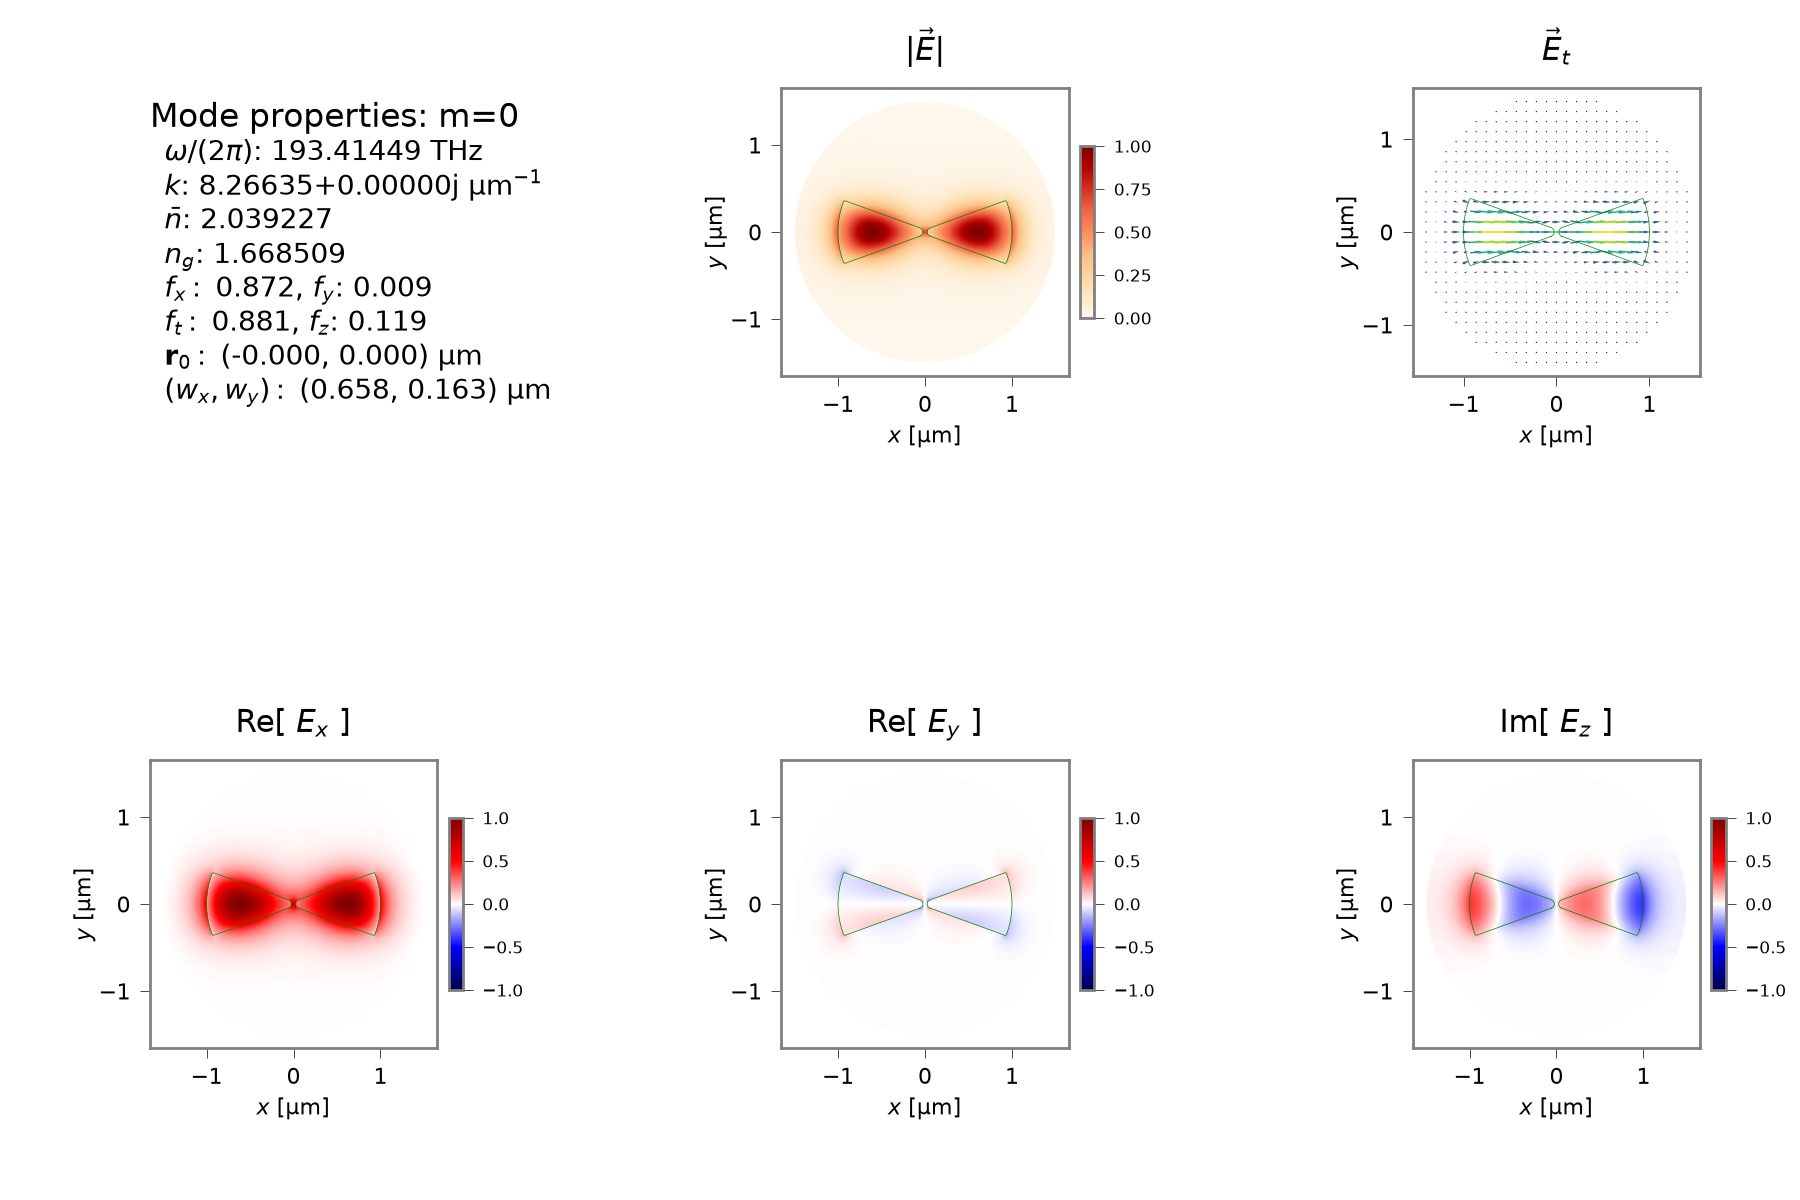

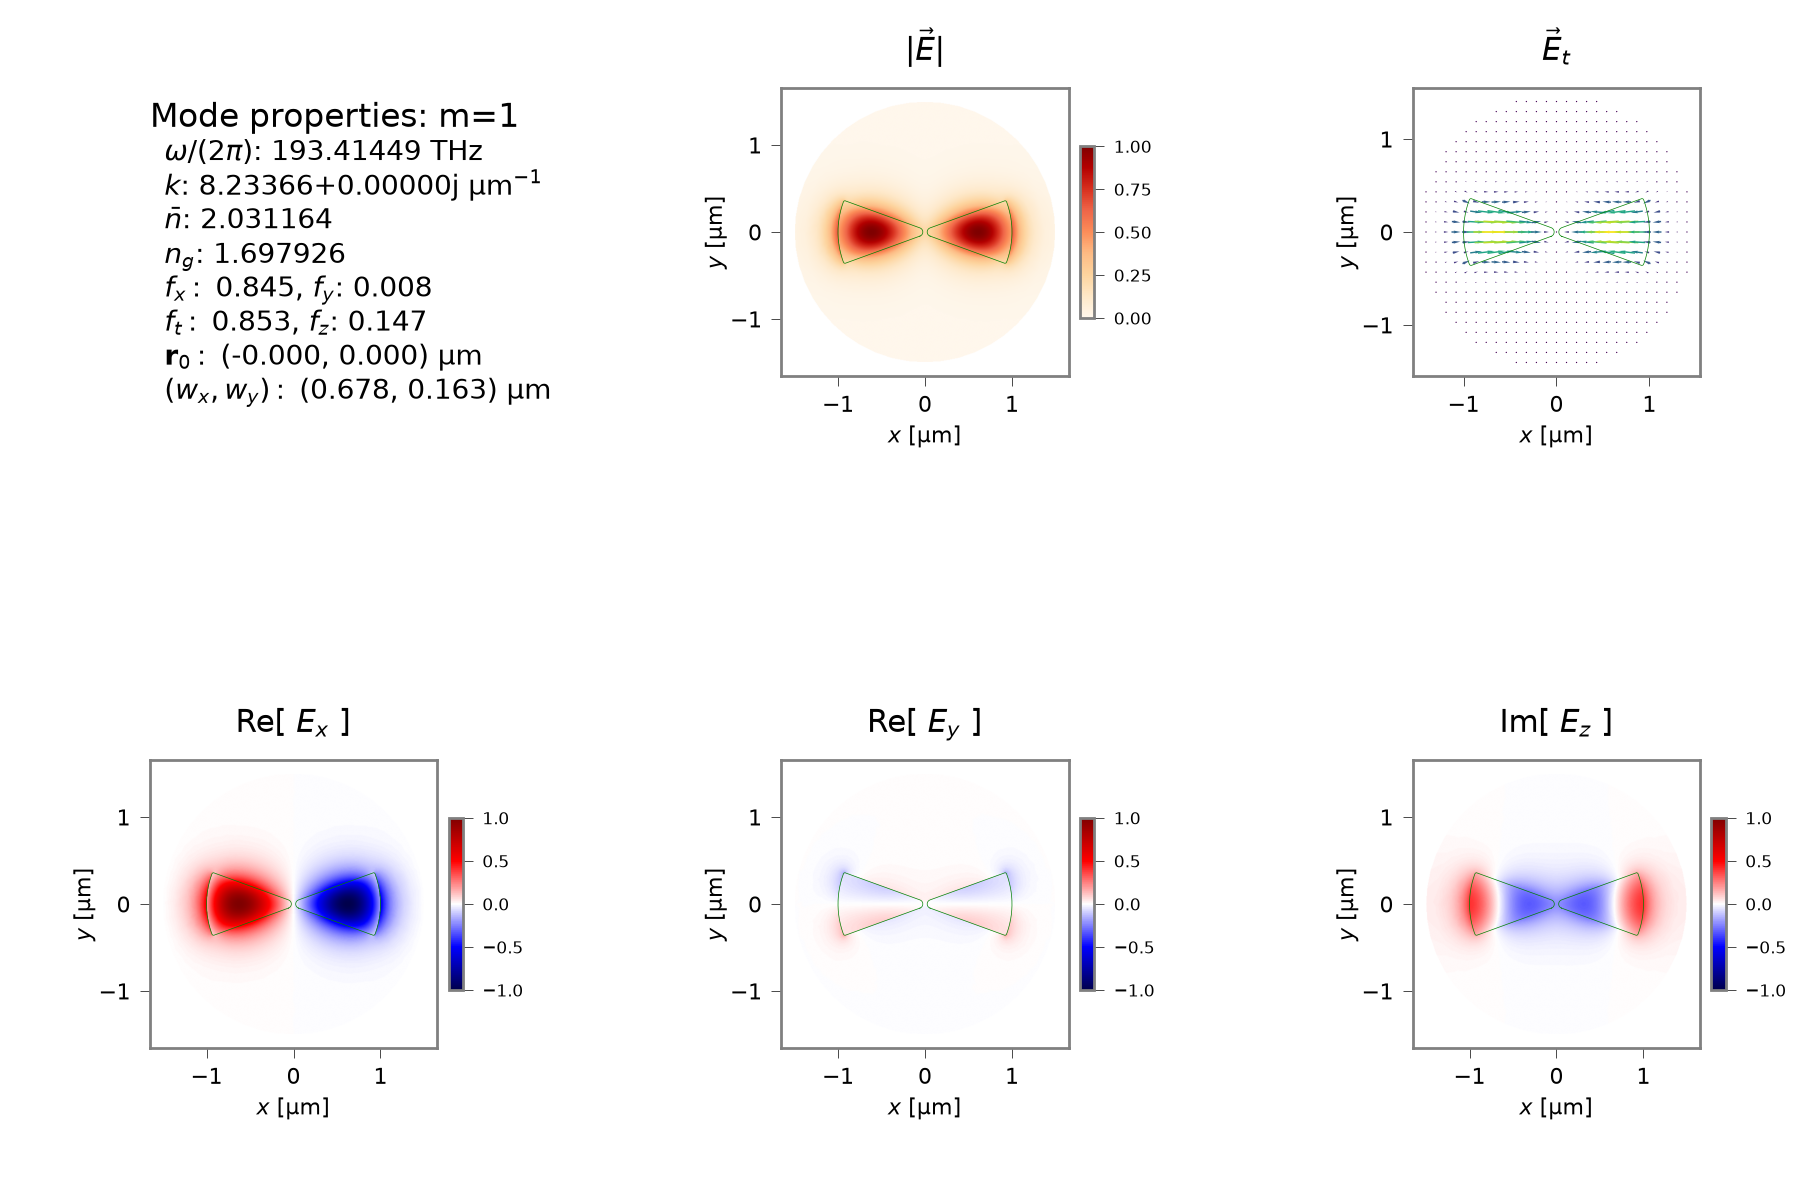

In [89]:
display_pngs(nbapp.outdir_fields_path(prefix), "E*_mode_0[01].png", imsize=(1600,1600), trim=(0.05, 0.1, 0.05, 0.15))

We can see the first mode is $x$-polarised with a strong slot effect.

The second mode is $y$-polarised but not confined and we don't see the bowtie effect of the in-plane fields in Bille-Lauridsen and Mork.


## Horizontal field cuts at $y = 0$

The horizontal cut passes through the two rounded tips and the central gap. 
Comparing the first two modes along this line makes their symmetry and gap confinement easy to see.

The slot effect is clear in the zeroth mode. 
The first (unconfined) mode has a central bump but it does not have the growing field in the inclusion (power law or otherwise) that we are looking for.

Plotting 1D cuts of electric fields of 2 optical modes in range m=[0,1]:
  Progress: |xxxxxxxxxxxxxxxxxxxx| 100.0% 


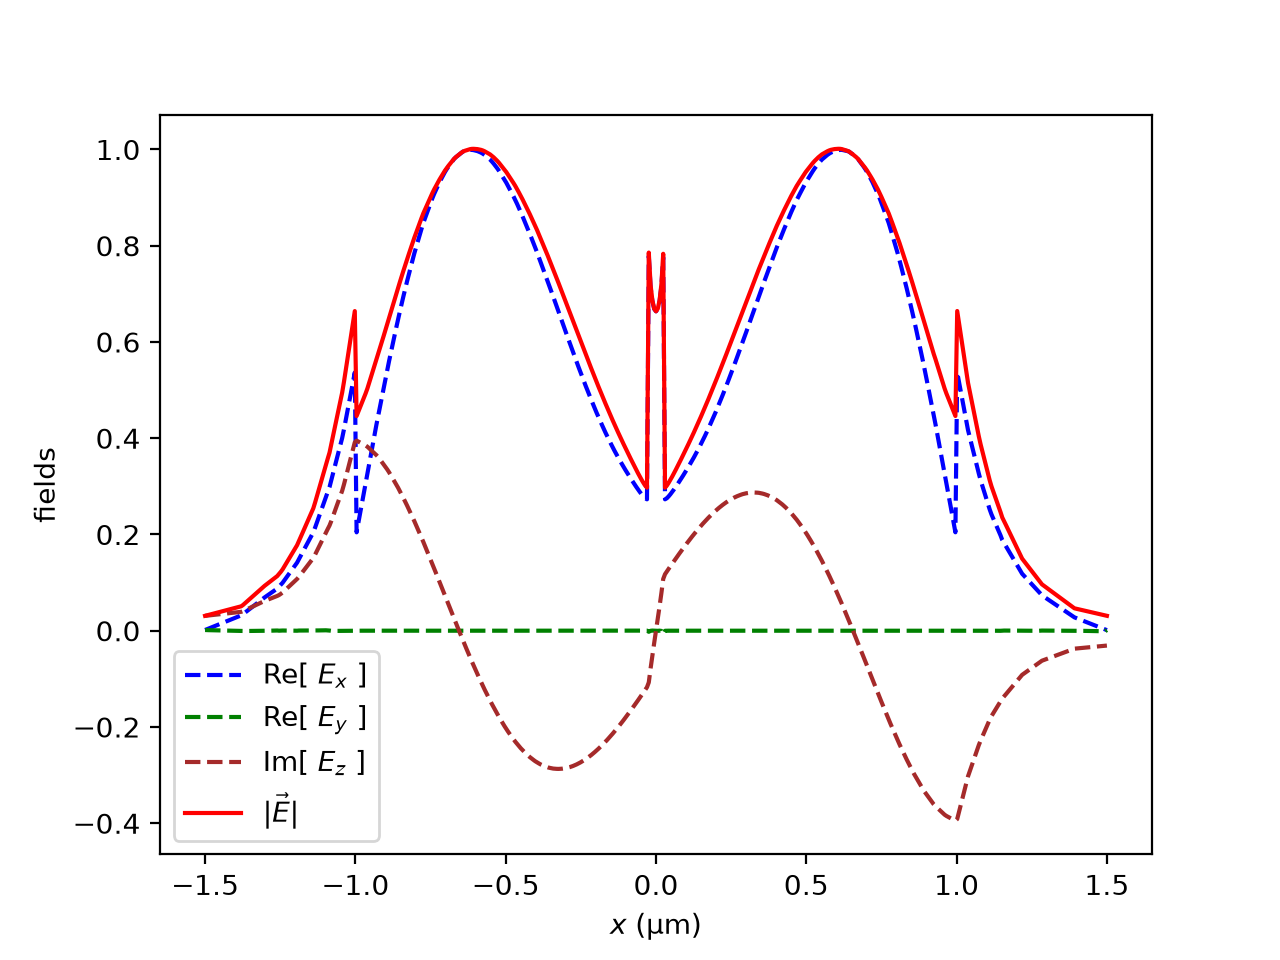

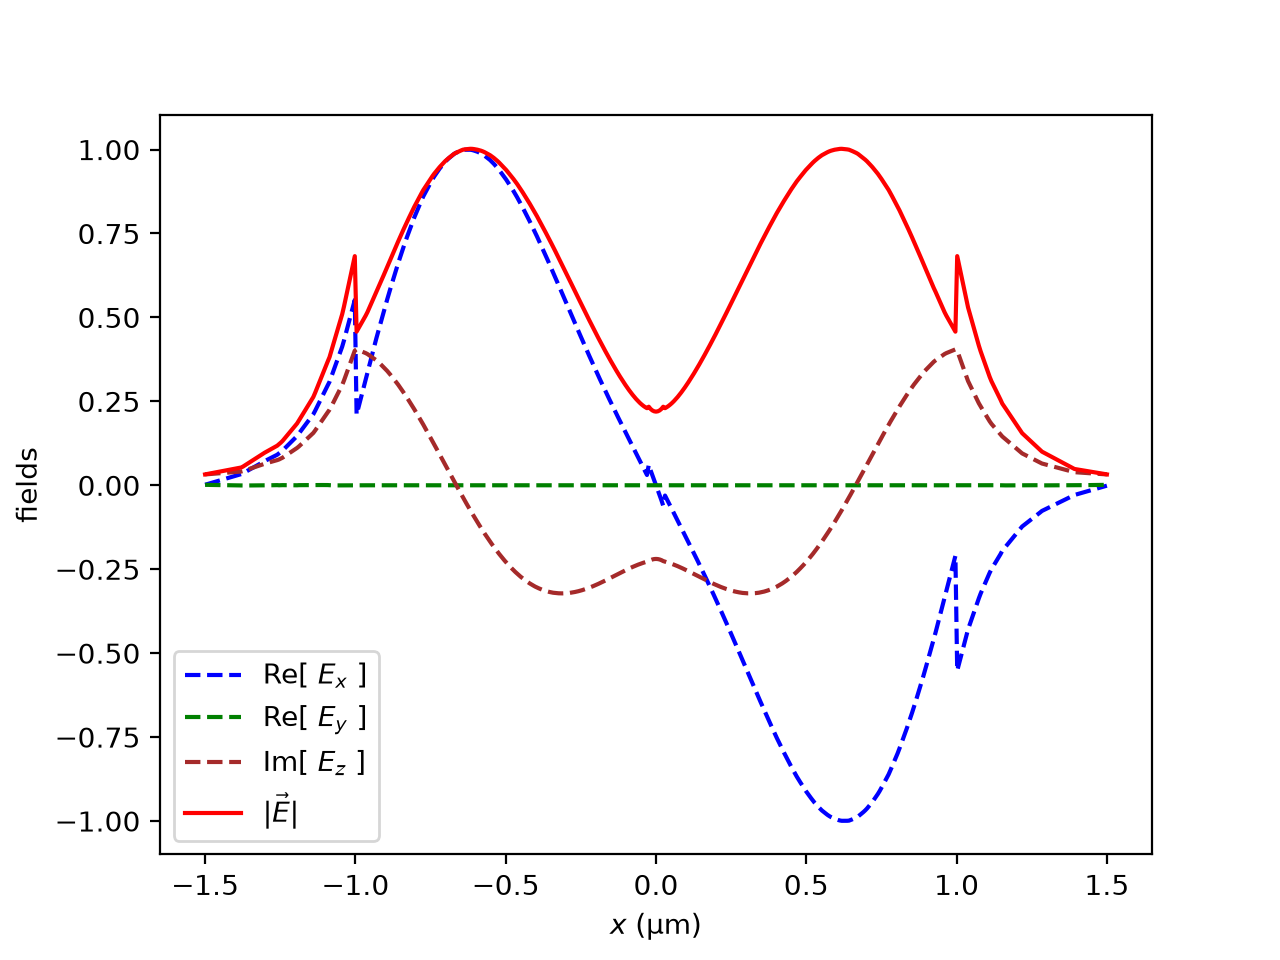

In [90]:
sim_EM.plot_modes_1D("y", 0, mode_indices=range(2))
display_pngs(nbapp.outdir_fields_path(prefix), "E*_mode_0[01]_ycut*.png")

## Elastic modes

In [91]:
q_AC = 4e7

sim_AC = wguide.calc_AC_modes(nmodes_sim_AC, q_AC, EM_sim=sim_EM)


 The final elastic sim mesh has 7109 nodes, 3542 mesh elements and 3 element types (materials).
 The material index table is: {1: 1, 2: 2, 3: 3} 

 There are 3 active materials:
   SiO2_2023_Steel,     rho = 2.200 g/cc, v_i = [5.9516, 3.7528, 3.7528] km/s.
   As2S3_2023_Steel,    rho = 3.200 g/cc, v_i = [2.4303, 1.4197, 1.4197] km/s.
   As2S3_2023_Steel,    rho = 3.200 g/cc, v_i = [2.4303, 1.4197, 1.4197] km/s.


Calculating elastic modes
doing AC mode power

 -----------------------------------------------
 AC FEM: 
   - assembling linear system:
           3542 mesh elements
           7109 mesh nodes
          21327 linear equations
         734067 nonzero elements
          0.161 % sparsity
             51 MB est. working memory 

       cpu time = .02 secs, wall time = .02 secs

  - solving linear system: 

      solving eigensystem
         cpu time = 83.71 secs, wall time = 2.74 secs

      assembling modes
         cpu time = 1.03 secs, wall time = .03 secs
 ------------------

In [92]:
print("\nAcoustic mode frequencies (GHz):")

acout_max=10
v_ac_nu = sim_AC.nu_AC_all()[:acout_max]
for mode_index, frequency in enumerate(v_ac_nu):
    print(f"mode {mode_index:2d}, {np.real(frequency) * 1e-9:.6f}")


Acoustic mode frequencies (GHz):
mode  0, 13.517540
mode  1, 13.517883
mode  2, 13.547049
mode  3, 13.551641
mode  4, 13.581218
mode  5, 13.582898
mode  6, 13.588378
mode  7, 13.591398
mode  8, 13.593852
mode  9, 13.595377


## Mode profiles

None of the following look much like what we are hunting.

In [93]:
sim_AC.plot_modes(mode_indices=acout_m, quiver_points=20)
sim_AC.plot_modes_1D("y", 0, mode_indices=acout_m)

Plotting displacement fields of 50 acoustic modes in range m=[0,49]:
Structure has raw domain (x,y) =  [-1.50000, 1.50000] x [-1.50000, 1.50000] (μm),
             mapped to (x',y') =  [-1.50000, 1.50000] x [-1.50000, 1.50000] (μm)
  Progress: |xxxxxxxxxxxxxxxxxxxx| 100.0% 
Plotting 1D cuts of displacement fields of 50 acoustic modes in range m=[0,49]:
  Progress: |xxxxxxxxxxxxxxxxxxxx| 100.0% 


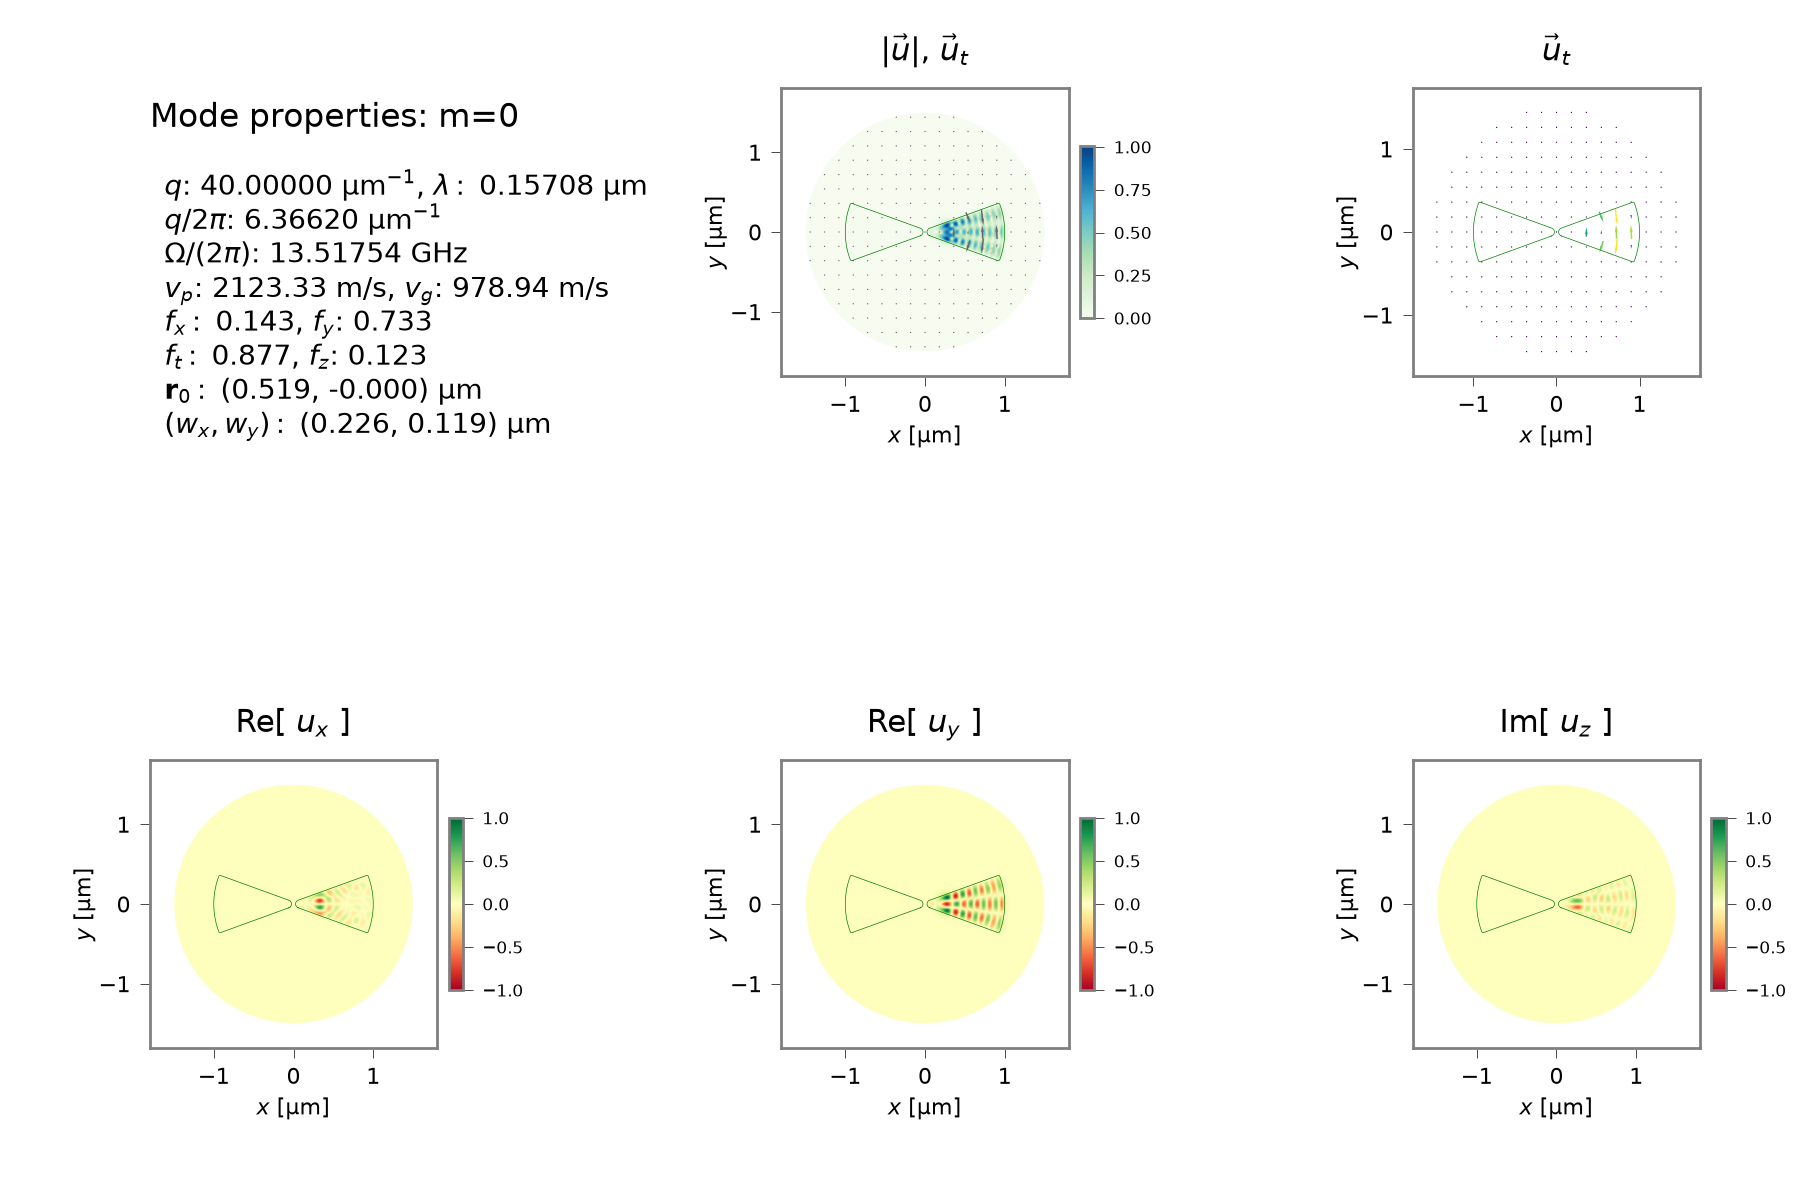

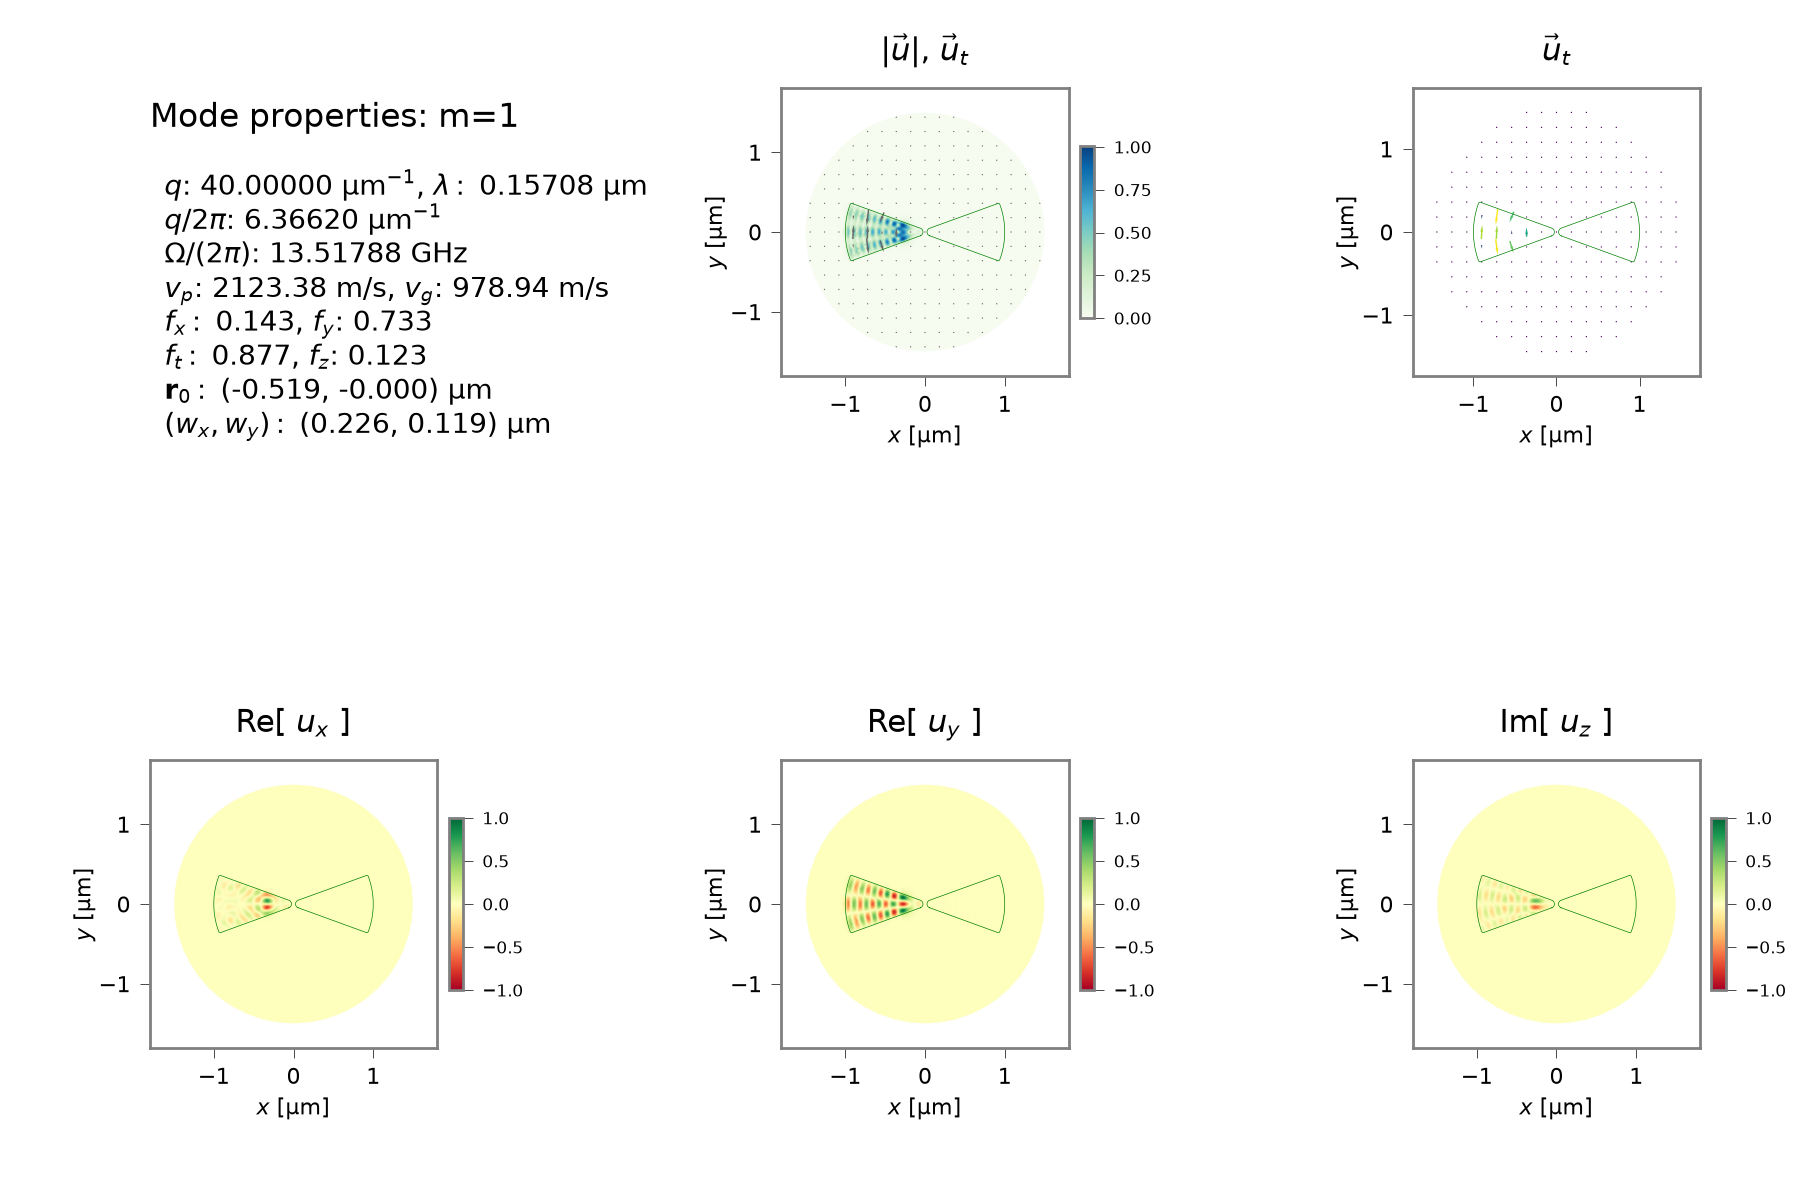

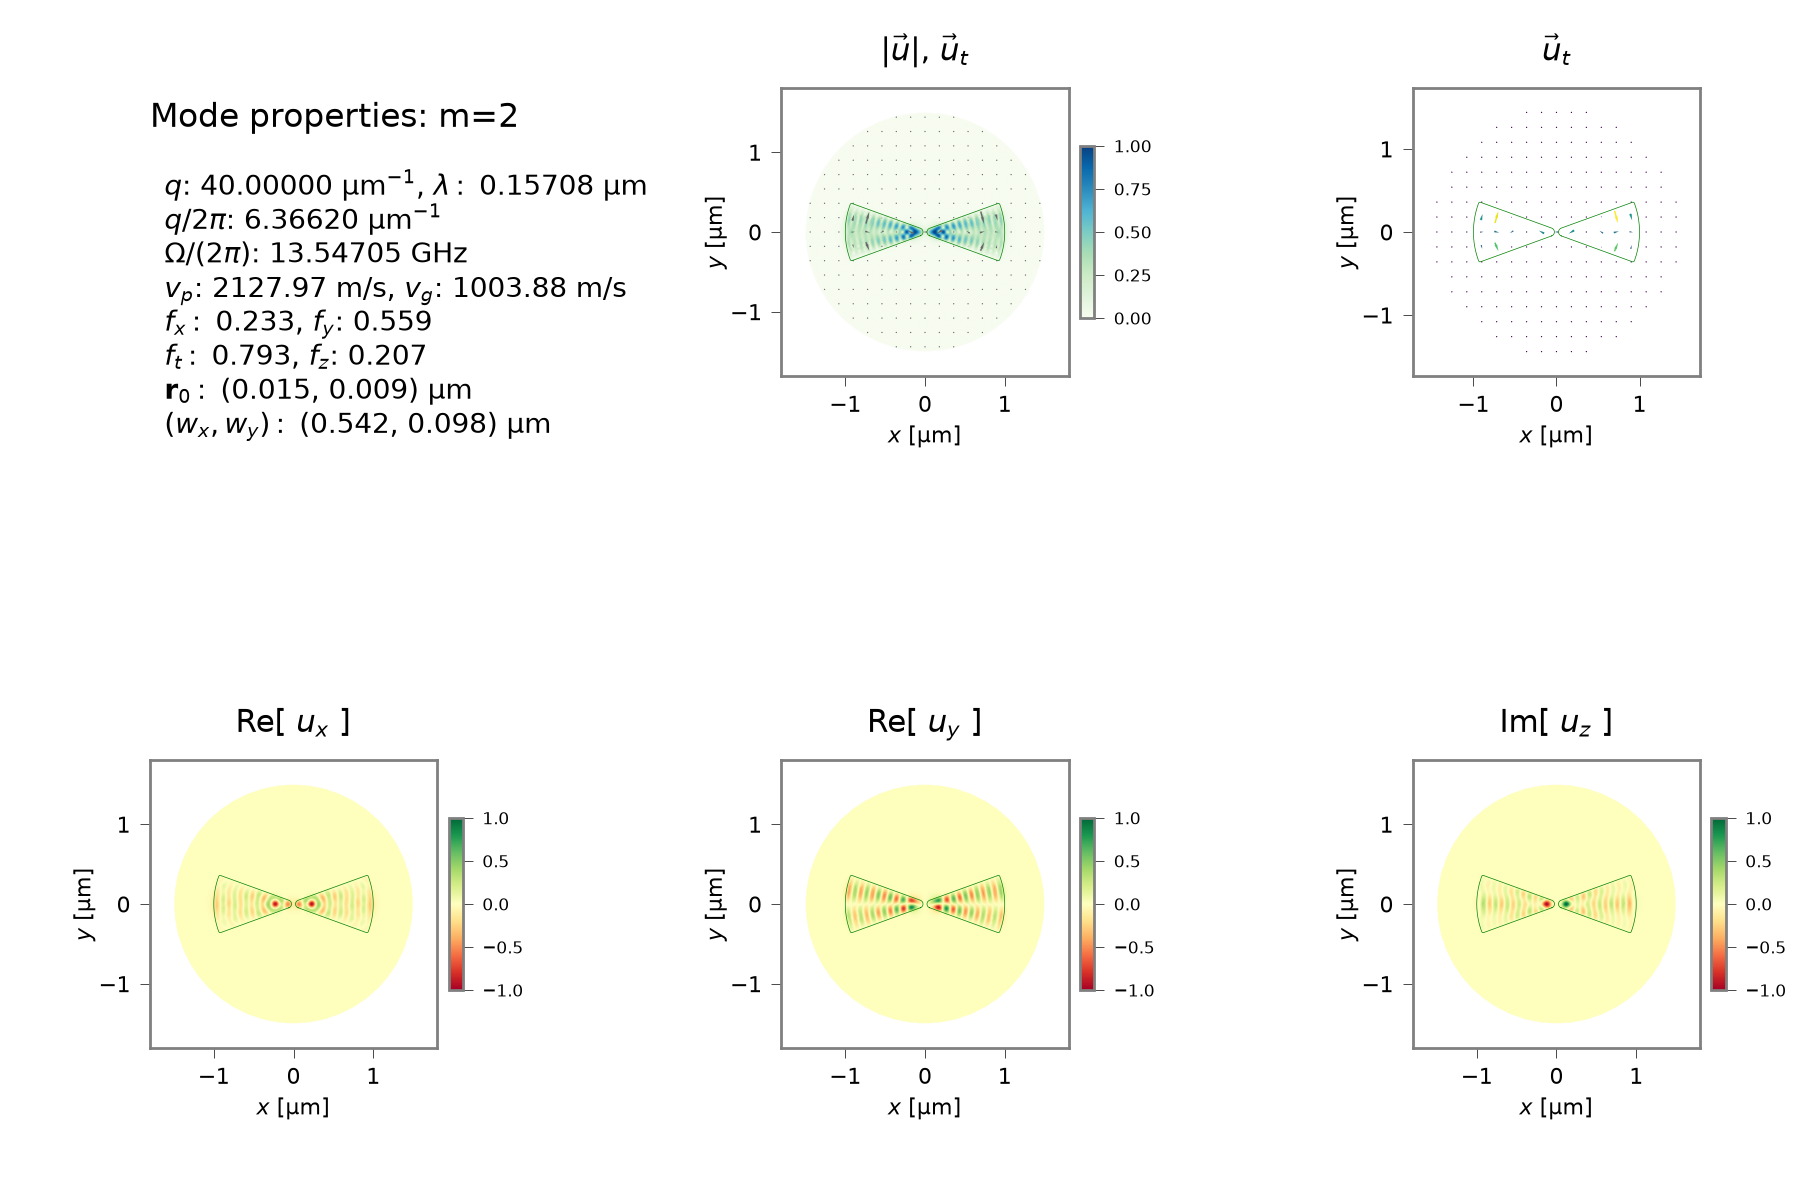

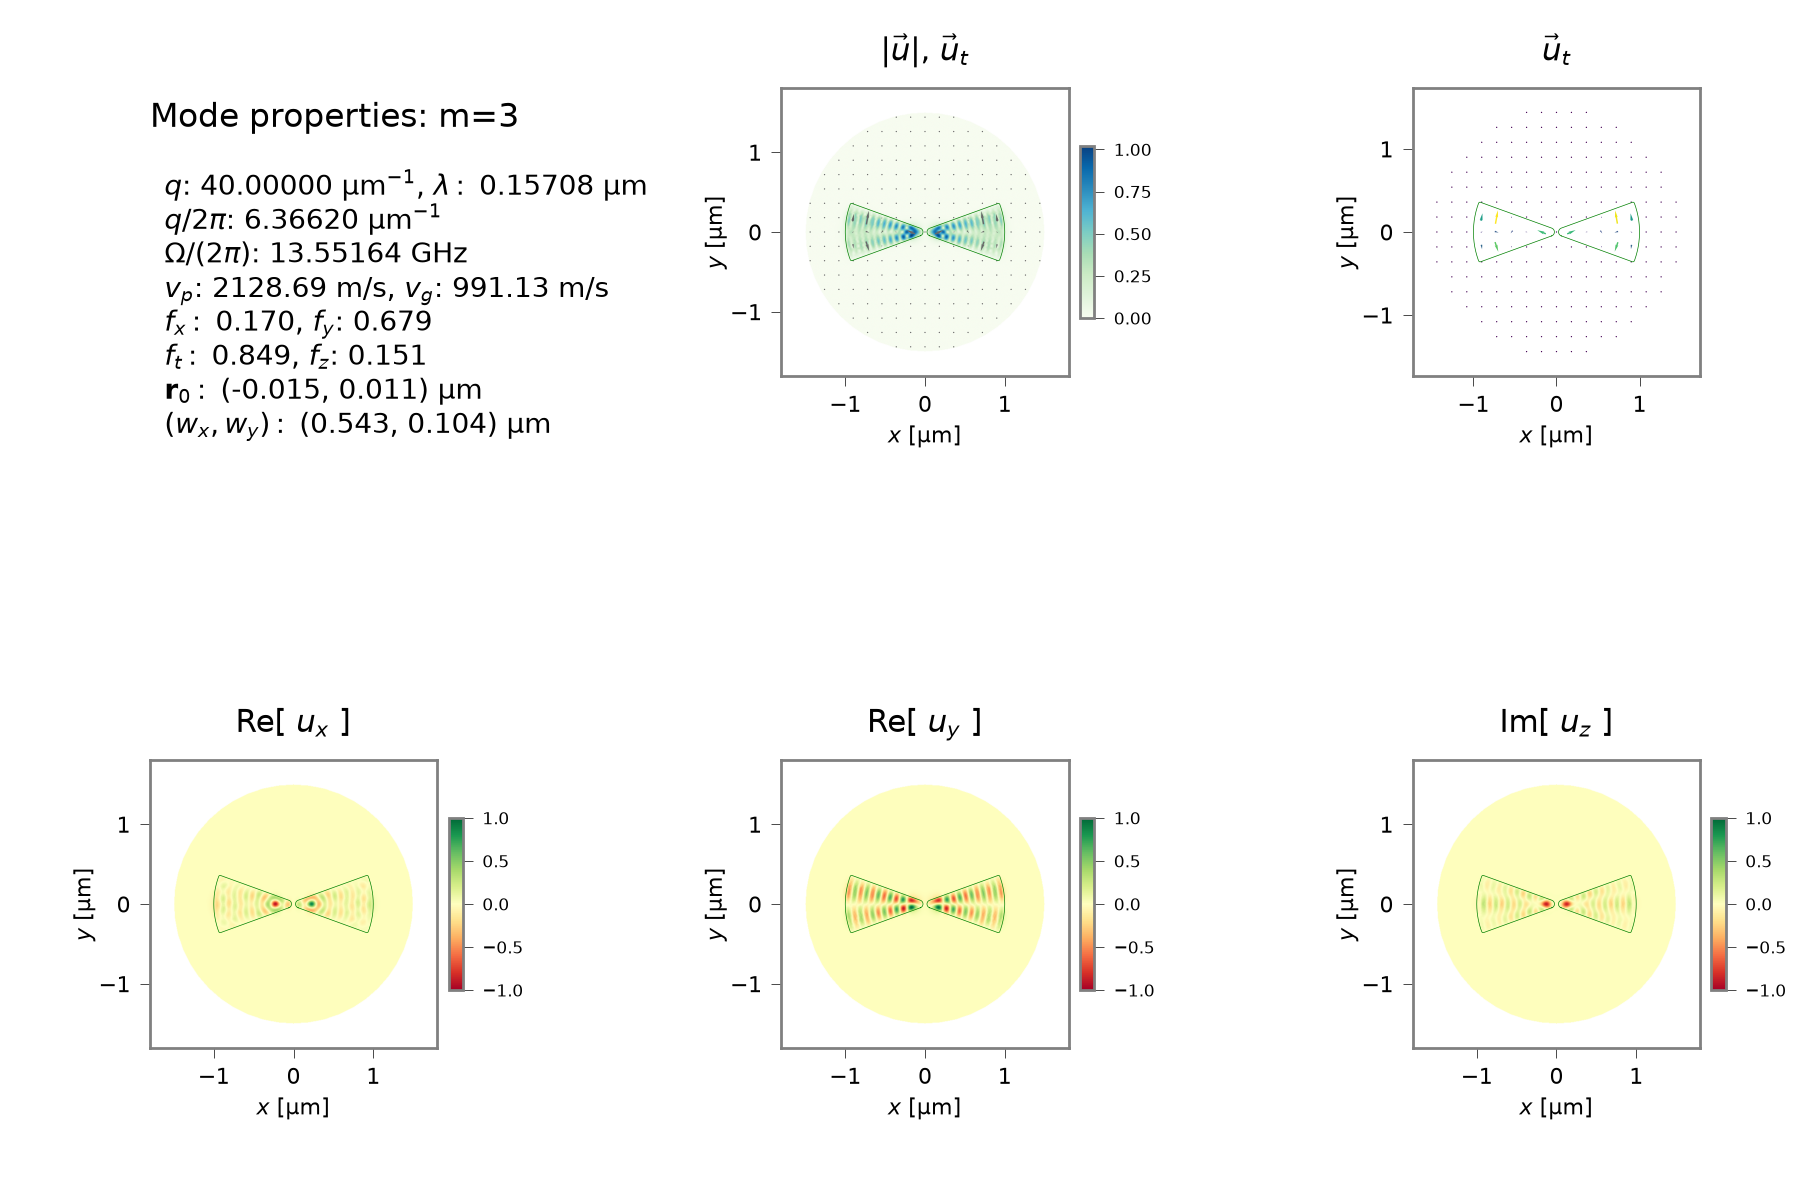

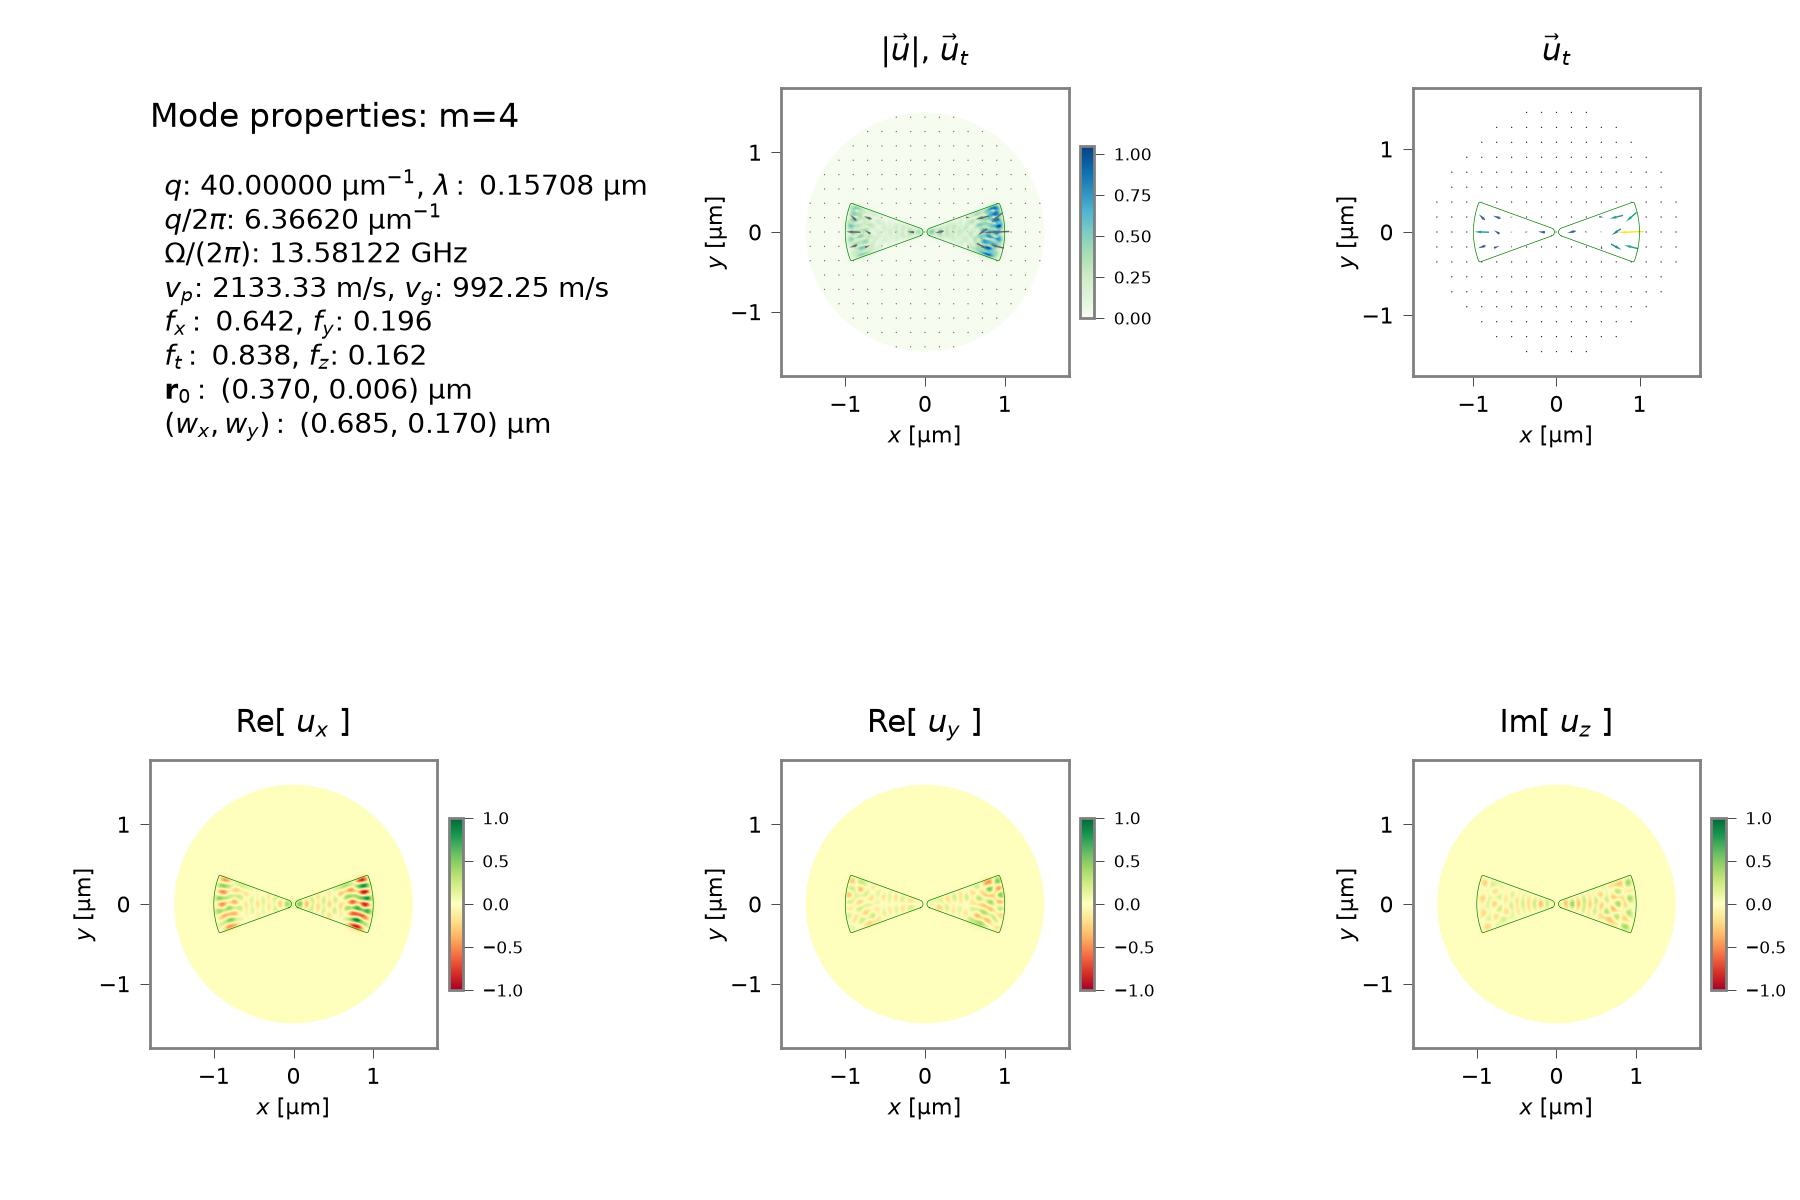

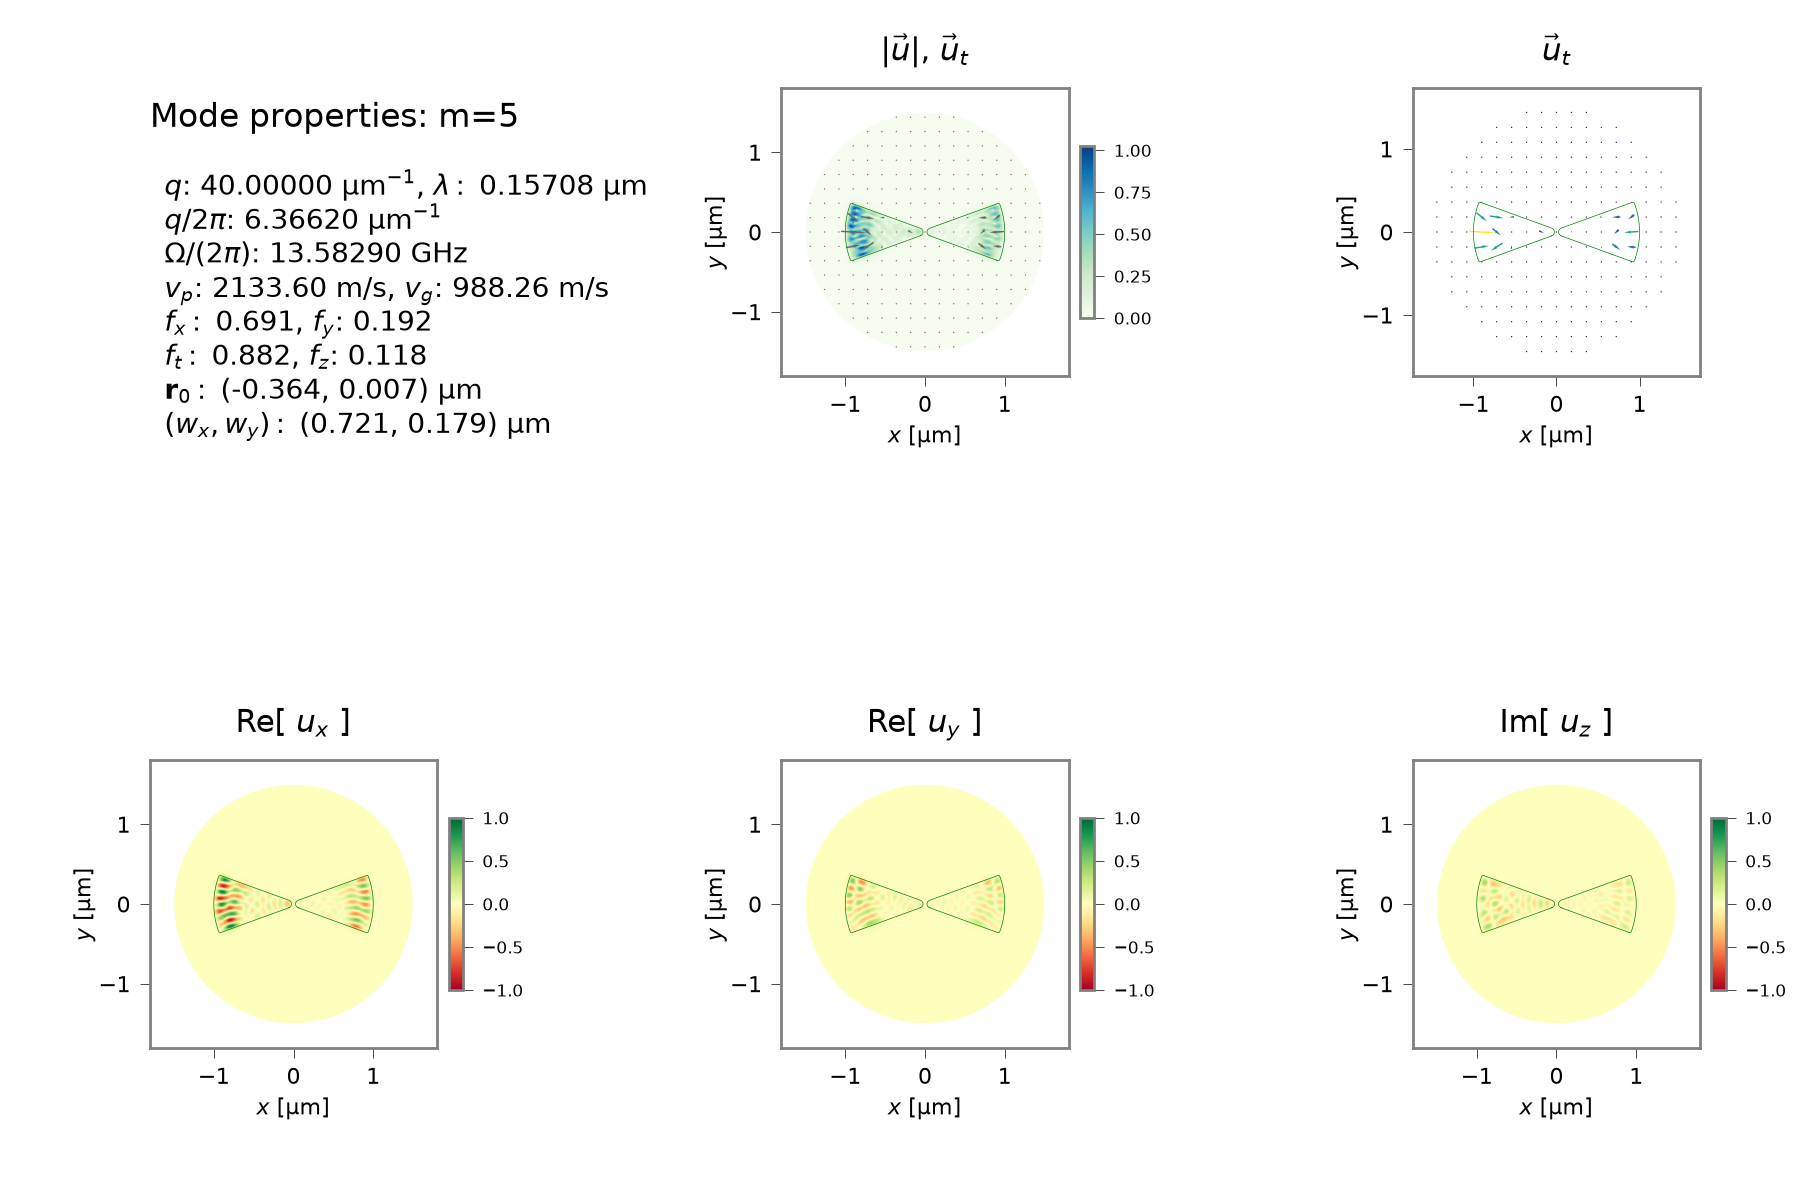

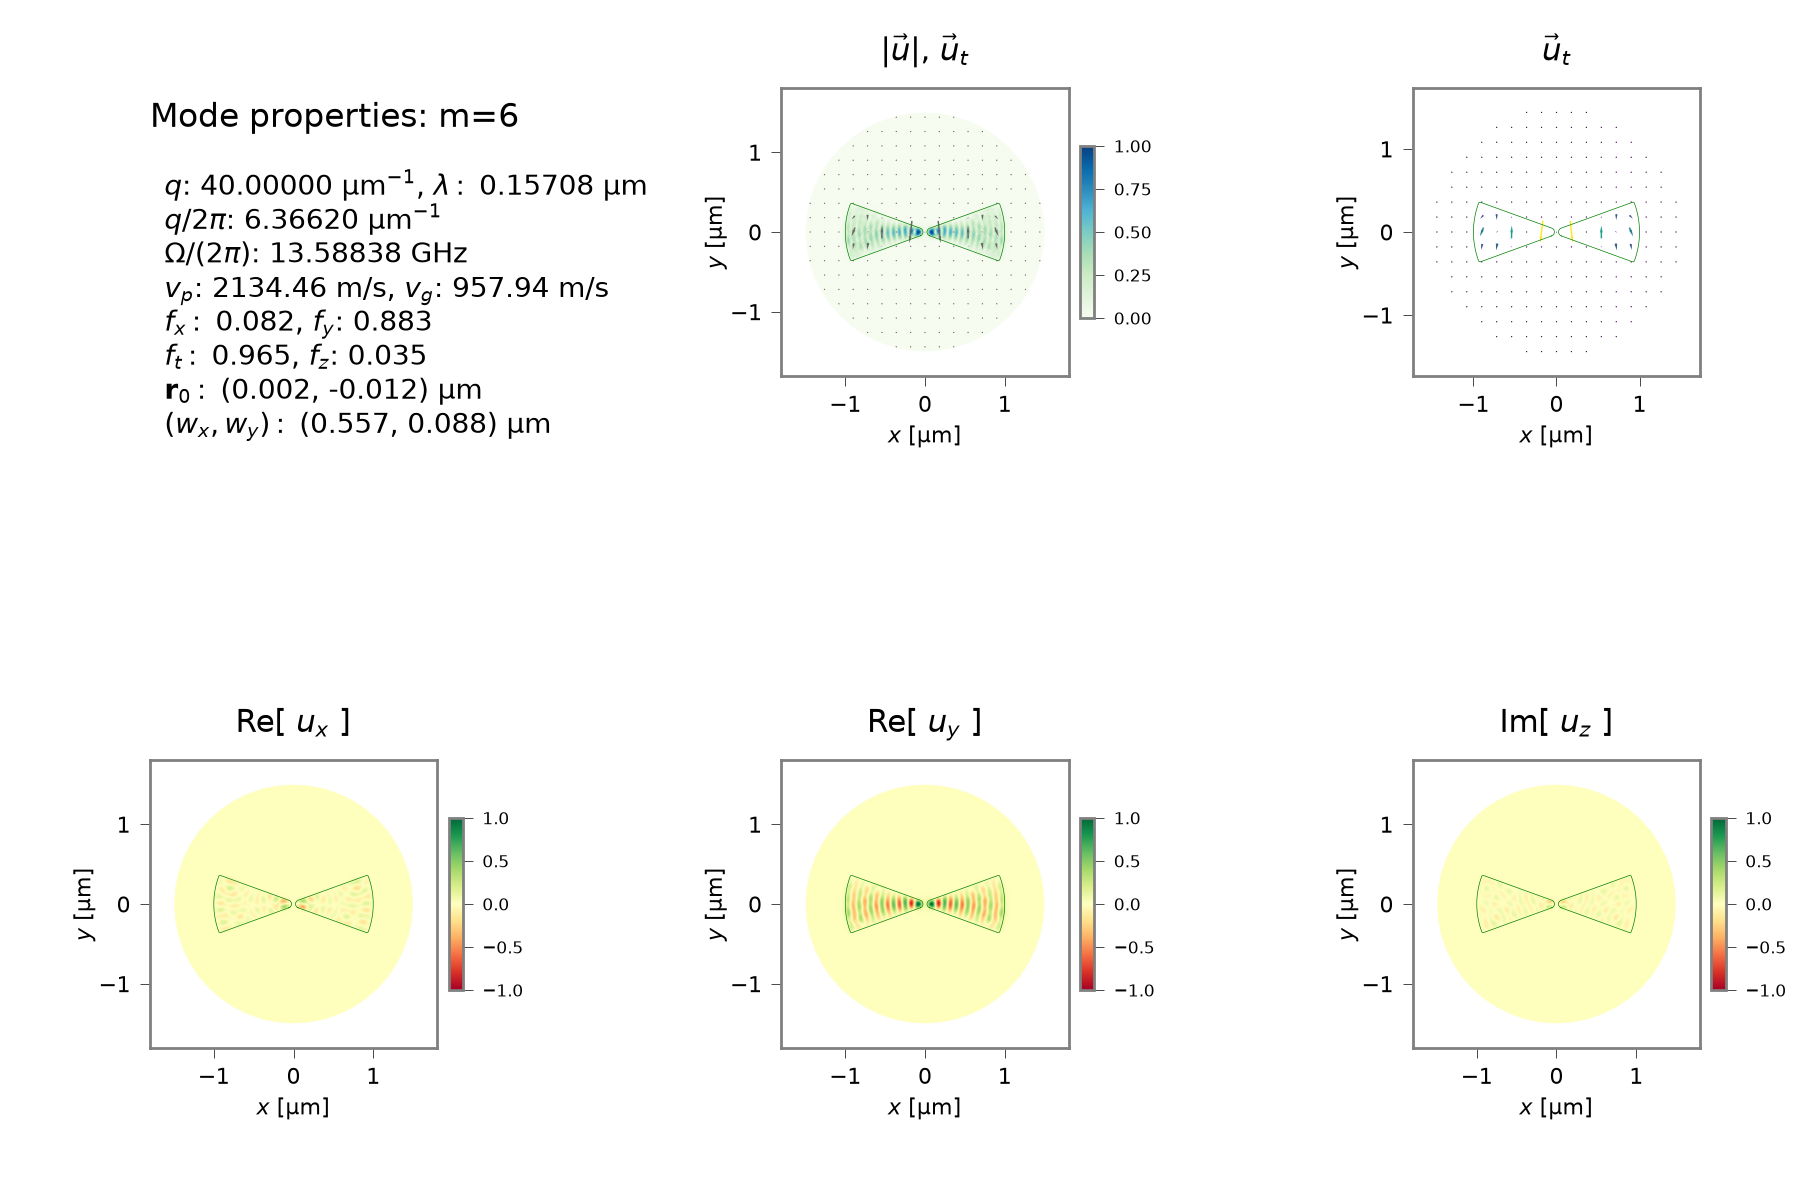

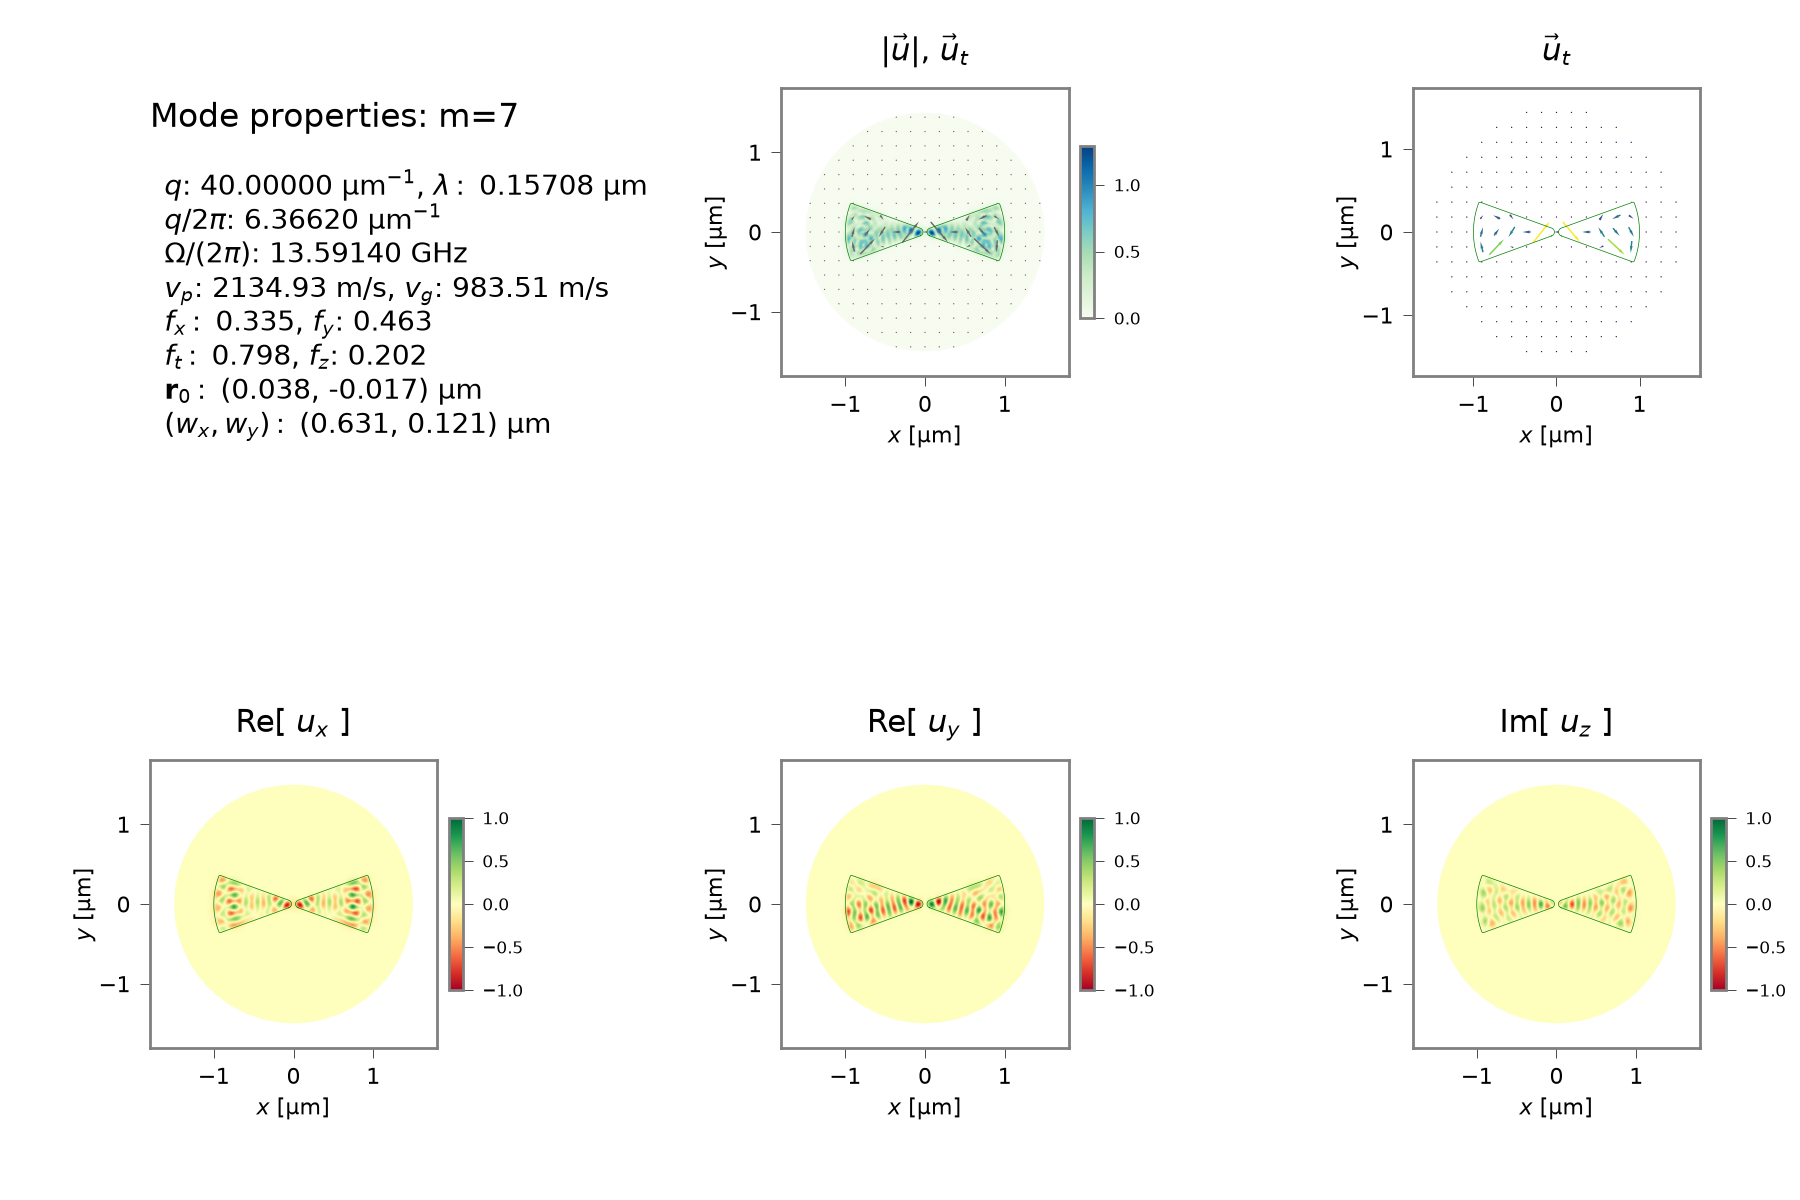

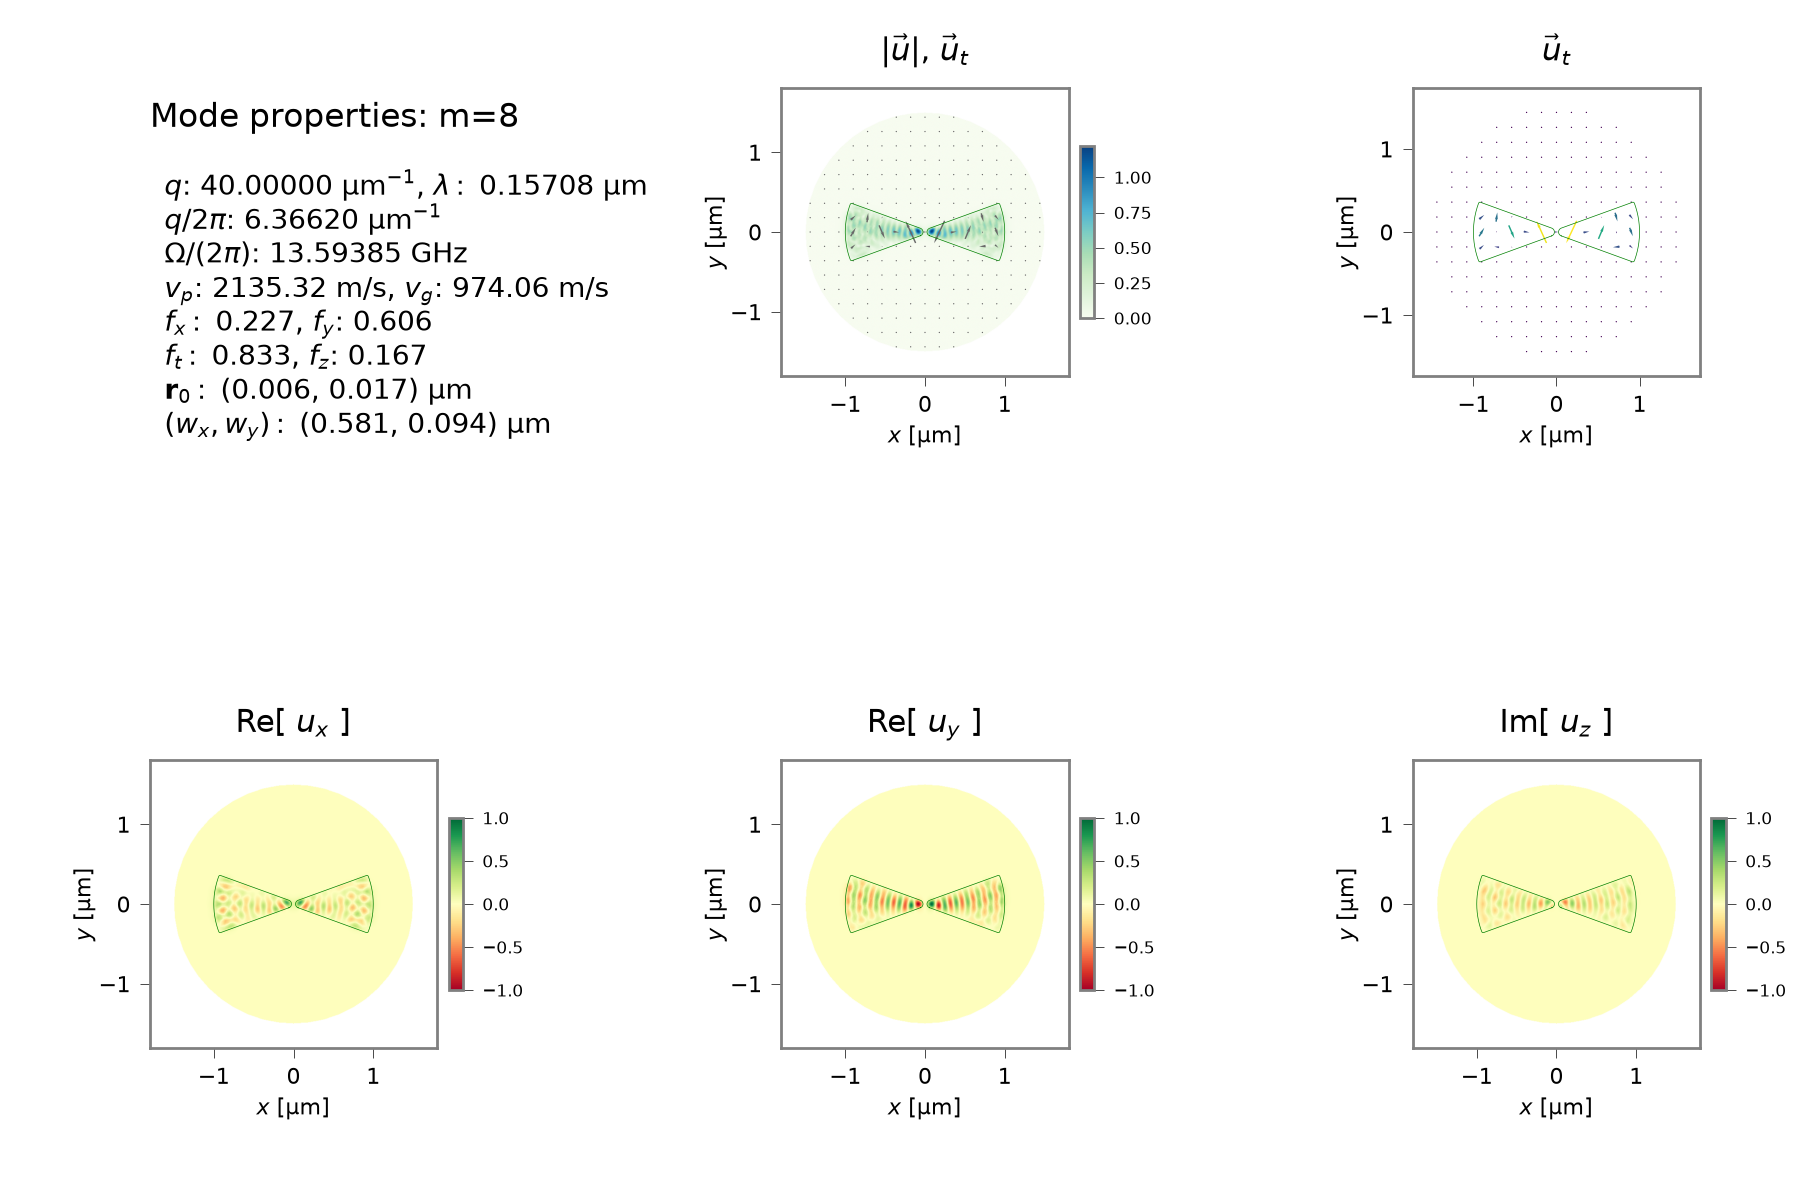

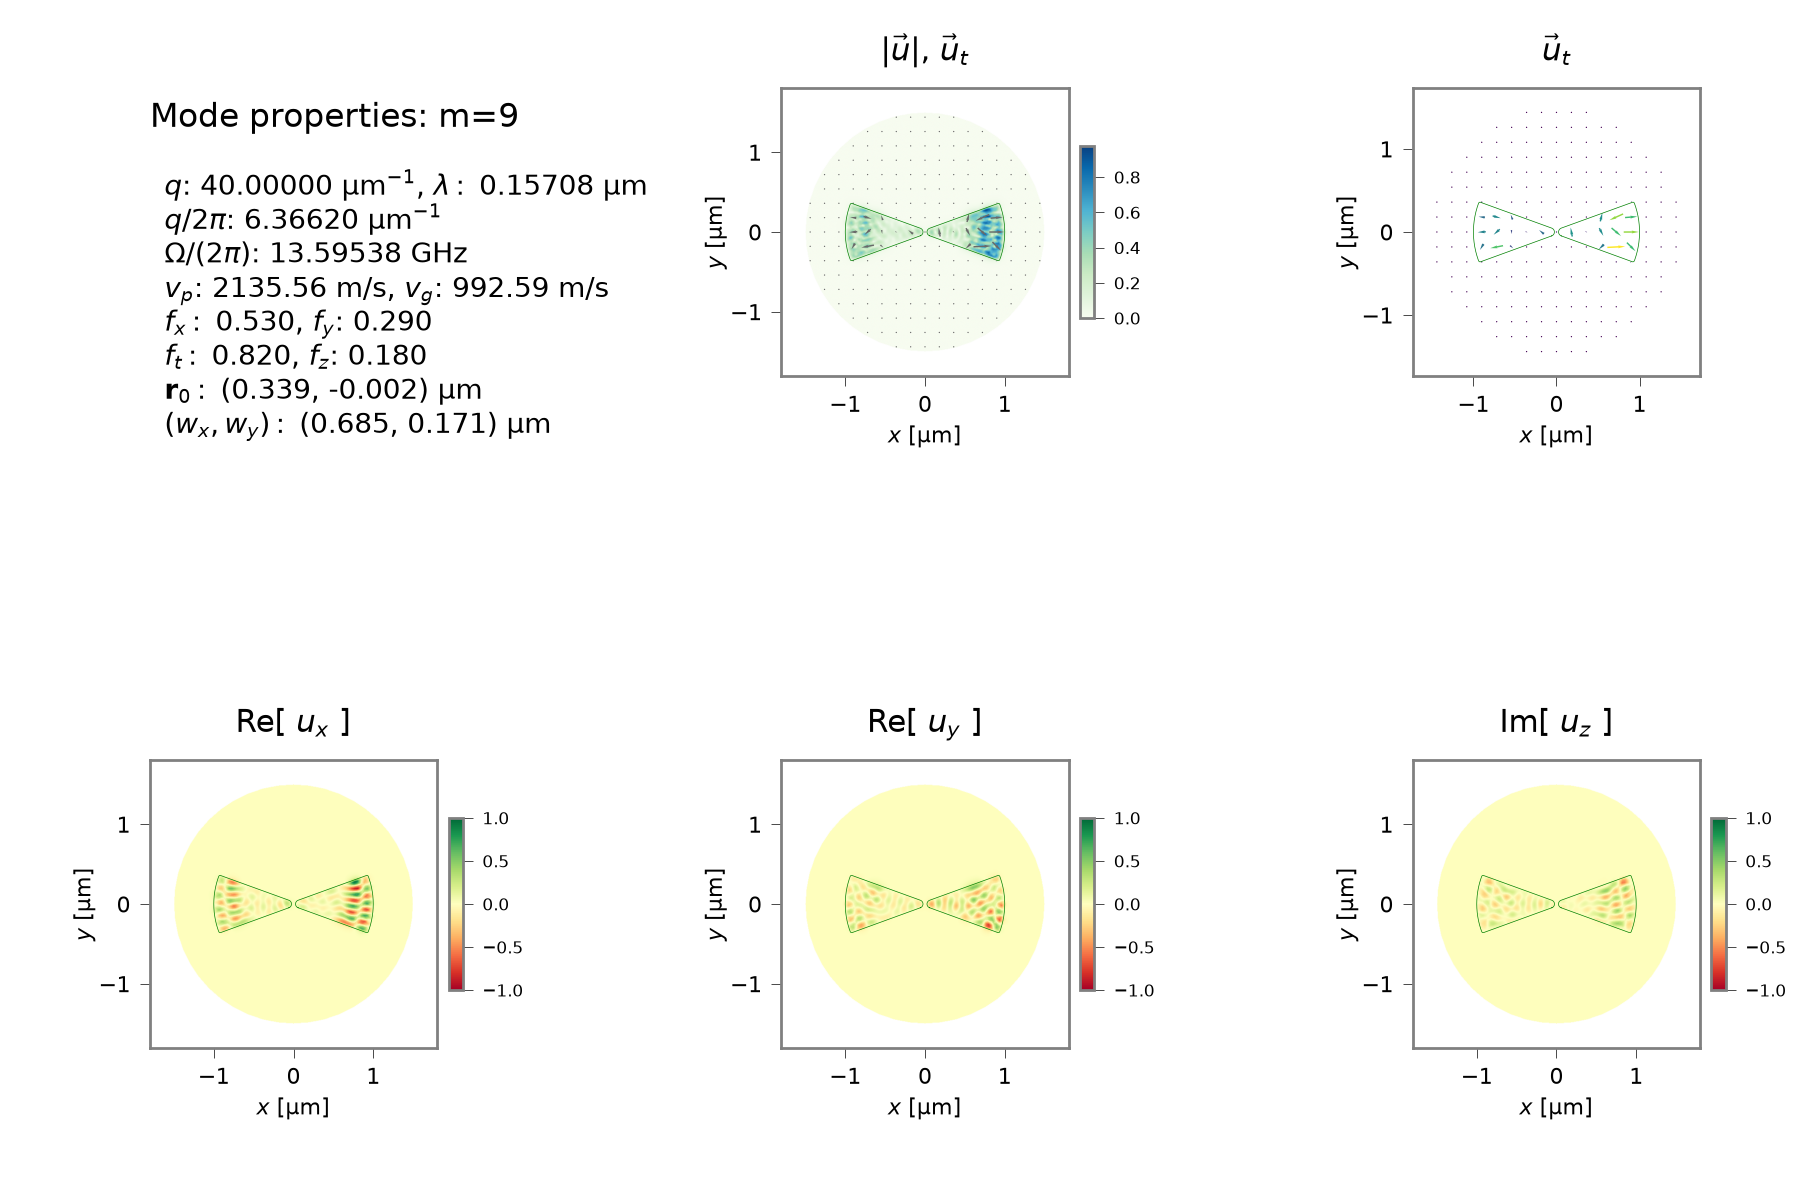

In [94]:
display_pngs(nbapp.outdir_fields_path(prefix), "AC*_mode_[0]?.png", imsize=(600,600), trim=(0.05, 0.1, 0.05, 0.15))

# Single inclusion

Let's drop to one inclusion and see if we can find the wavy wedge mode.

Also, we make the surrounding vacuum.


In [8]:
material_bkg = mat_vacuum
material_a = mat_chalcogenide

wguide_wedge = nbapp.make_structure(
    "rounded_wedge",
    domain_x,
    domain_y,
    rad_tip=rad_tip,
    rad_wg=rad_wg,
    alpha_tip=alpha_tip,
    bowlen_l=bowlen_l,
    rad_corner=rad_corner,
    material_bkg=material_bkg,
    material_a=material_a,
    material_b=material_b,
    lc_bkg=0.1,
    lc_refine_1=50.0,
    lc_refine_2=5.0,
)

 Calling Gmsh: 

In [9]:
fn_mesh_plot  = wguide_wedge.plot_mesh(prefix)
img_single(fn_mesh_plot, 'Design and mesh', 400)

In [10]:
index_plotter = wguide_wedge.get_structure_plotter_refractive_index()
[fn_ind_2D] = index_plotter.make_plot_2D(prefix)
[fn_ind_1D] = index_plotter.make_plot_1D_cut(prefix, "y", 0)

img_pair(fn_ind_2D, fn_ind_1D, 'Whole structure', 'y=0 cut', 300, 300)

    initial mesh has: 6457 nodes, 3216 elements. 


 The final EM sim mesh has 6457 nodes, 3216 elements and 2 element types (materials).
 There are 2 active materials:
  Vacuum,              n = 1.00000+0.00000j, mat. index = 1.
  As2S3_2023_Steel,    n = 2.45000+0.00000j, mat. index = 2.


## EM modes

As expected, the EM modes are uninterested in confinement near the apex and we just get modes of the whole inclusion. The first mode is $y$-polarised (TE-like) and the second is $x$-polarised (TM-like).

In [11]:
n_eff_estimate = material_a.refindex_n - 0.1
sim_EM = wguide_wedge.calc_EM_modes(nmodes_sim_EM, lambda_nm, n_eff=n_eff_estimate)

v_neff = sim_EM.neff_all()[:emout_max]
for mode_index, n_eff in enumerate(v_neff):
    print(f"mode {mode_index:2d}: n_eff = {n_eff:.6f}")

    initial mesh has: 6457 nodes, 3216 elements. 


 The final EM sim mesh has 6457 nodes, 3216 elements and 2 element types (materials).
 There are 2 active materials:
  Vacuum,              n = 1.00000+0.00000j, mat. index = 1.
  As2S3_2023_Steel,    n = 2.45000+0.00000j, mat. index = 2.


Calculating EM modes:
 Boundary conditions: Dirichlet

 -----------------------------------------------
 EM FEM: 
   - assembling linear system:
           3216 mesh elements
           6457 mesh nodes
          38665 linear equations (cscmat%n_dof)
        1322353 nonzero elements  (cscmat%n_nonz)
          0.088 % sparsity
             34 MB est. working memory 

       cpu time = .32 secs, wall time = .32 secs

  - solving linear system: 

      solving eigensystem
         cpu time = 81.79 secs, wall time = 2.72 secs

      assembling modes
         cpu time = 2.85 secs, wall time = .34 secs
 -----------------------------------------------
  Calculating EM mode powers...
using curvilinear eleme

Plotting electric fields of 5 optical modes in range m=[0,4]:
Structure has raw domain (x,y) =  [-1.50000, 1.50000] x [-1.50000, 1.50000] (μm),
             mapped to (x',y') =  [-1.50000, 1.50000] x [-1.50000, 1.50000] (μm)
  Progress: |xxxxxxxxxxxxxxxxxxxx| 100.0% 


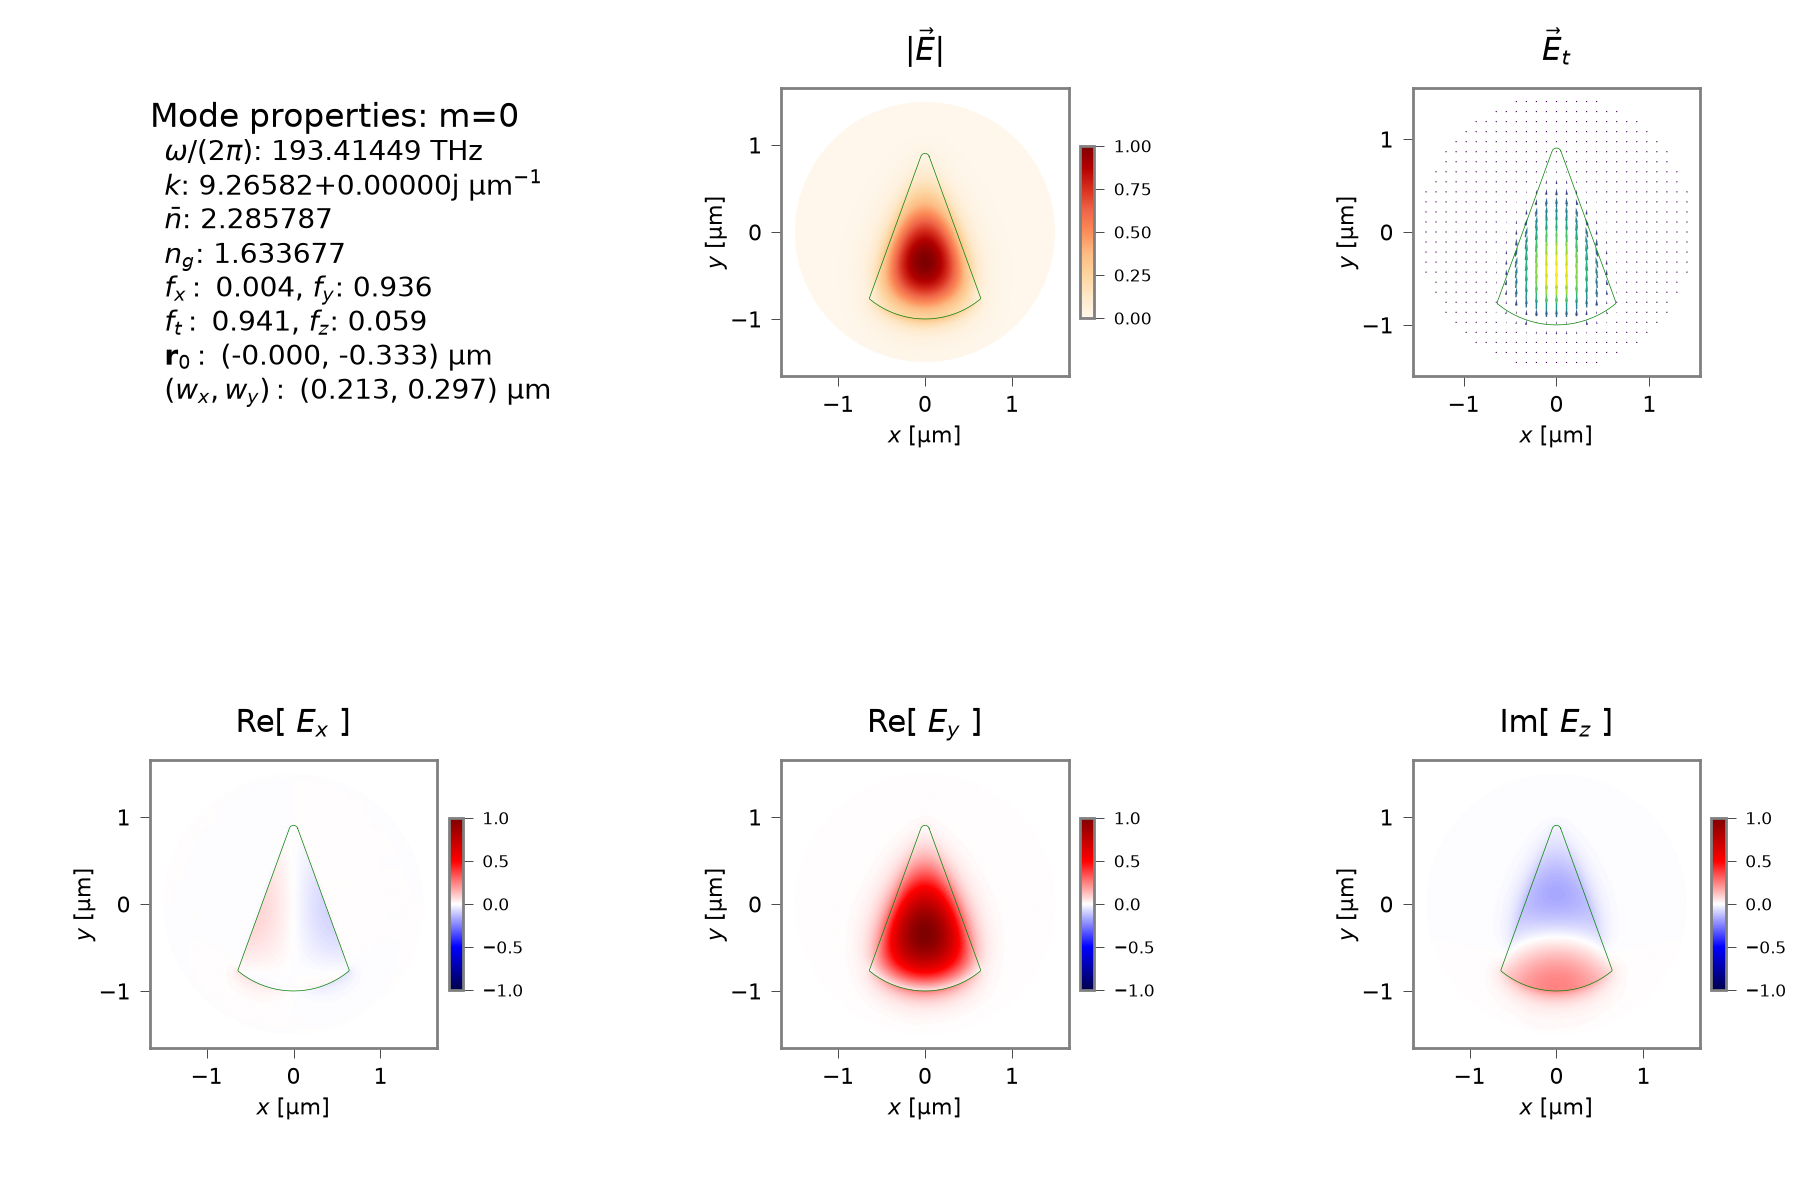

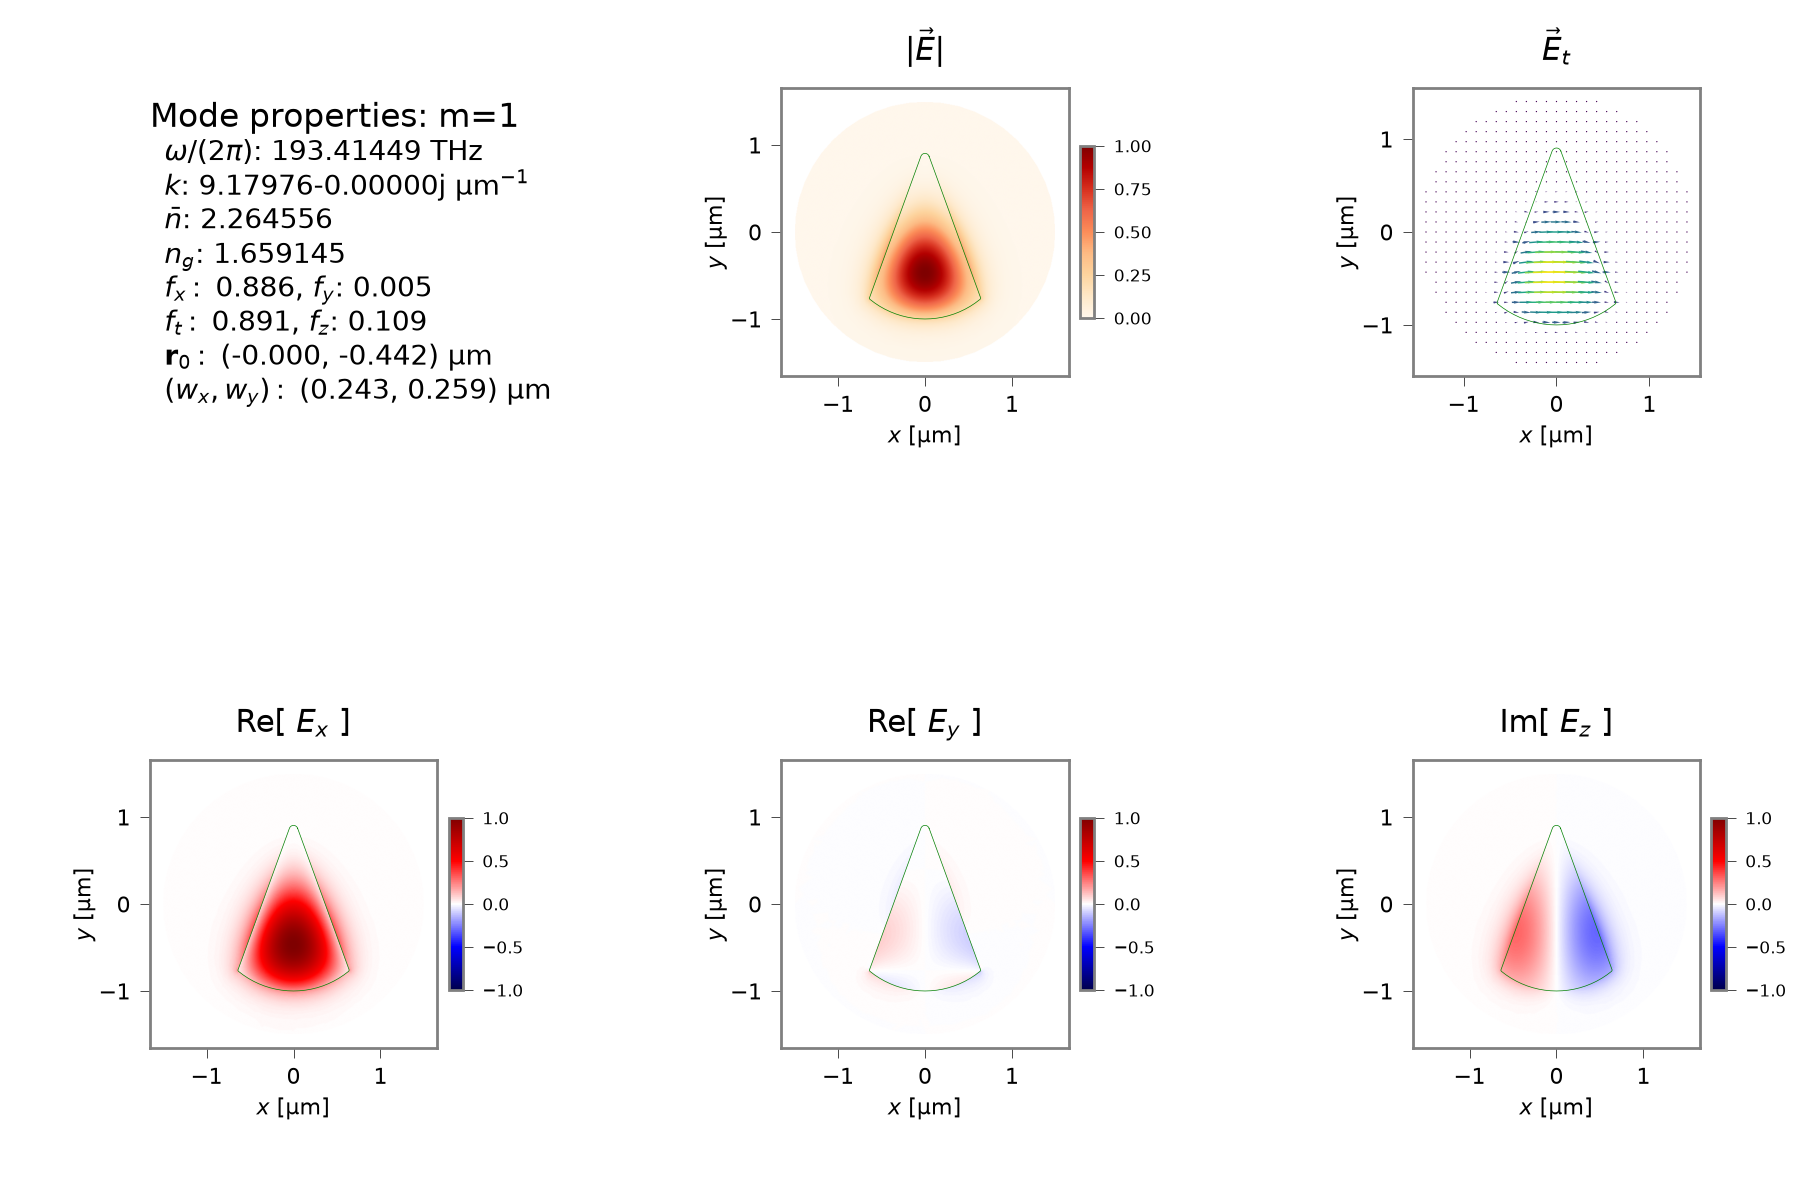

In [12]:
sim_EM.plot_modes(mode_indices=emout_m, hide_vector_field=True)
display_pngs(nbapp.outdir_fields_path(prefix), "E*_mode_0[01].png", imsize=(1600,1600), trim=(0.05, 0.1, 0.05, 0.15))

## Elastic modes

Now let's go for the elastic modes and see if we can find the wavy wedge mode.

In [19]:
q_AC = 4e6

sim_AC = wguide_wedge.calc_AC_modes(nmodes_sim_AC, q_AC, EM_sim=sim_EM)


 The final elastic sim mesh has 4519 nodes, 2184 mesh elements and 1 element types (materials).
 The material index table is: {2: 1} 

 There are 2 active materials:
   As2S3_2023_Steel,    rho = 3.200 g/cc, v_i = [2.4303, 1.4197, 1.4197] km/s.
   As2S3_2023_Steel,    rho = 3.200 g/cc, v_i = [2.4303, 1.4197, 1.4197] km/s.


Calculating elastic modes

 -----------------------------------------------
 AC FEM: 
doing AC mode power
   - assembling linear system:
           2184 mesh elements
           4519 mesh nodes
          13557 linear equations
         457497 nonzero elements
          0.249 % sparsity
             32 MB est. working memory 

       cpu time = .01 secs, wall time = .01 secs

  - solving linear system: 

      solving eigensystem
         cpu time = 48.49 secs, wall time = 1.59 secs

      assembling modes
         cpu time = .59 secs, wall time = .02 secs
 -----------------------------------------------

Doing AC mode energy
Acoustic loss calculation with intrinsic

In [20]:
sim_AC.plot_modes(mode_indices=acout_m, quiver_points=20)
#sim_AC.plot_modes_1D("y", 0, mode_indices=acout_m)

Plotting displacement fields of 50 acoustic modes in range m=[0,49]:
Structure has raw domain (x,y) =  [-0.63915, 0.63915] x [-1.00000, 0.90381] (μm),
             mapped to (x',y') =  [-0.63915, 0.63915] x [-1.00000, 0.90381] (μm)
  Progress: |xxxxxxxxxxxxxxxxxxxx| 100.0% 


Yes!, Scattered amongst the following, including the zeroth, are the previously found wedge modes, nicely localised at 
the tip.

Question is: can we keep them if the surrounding matrix is non-vacuum?

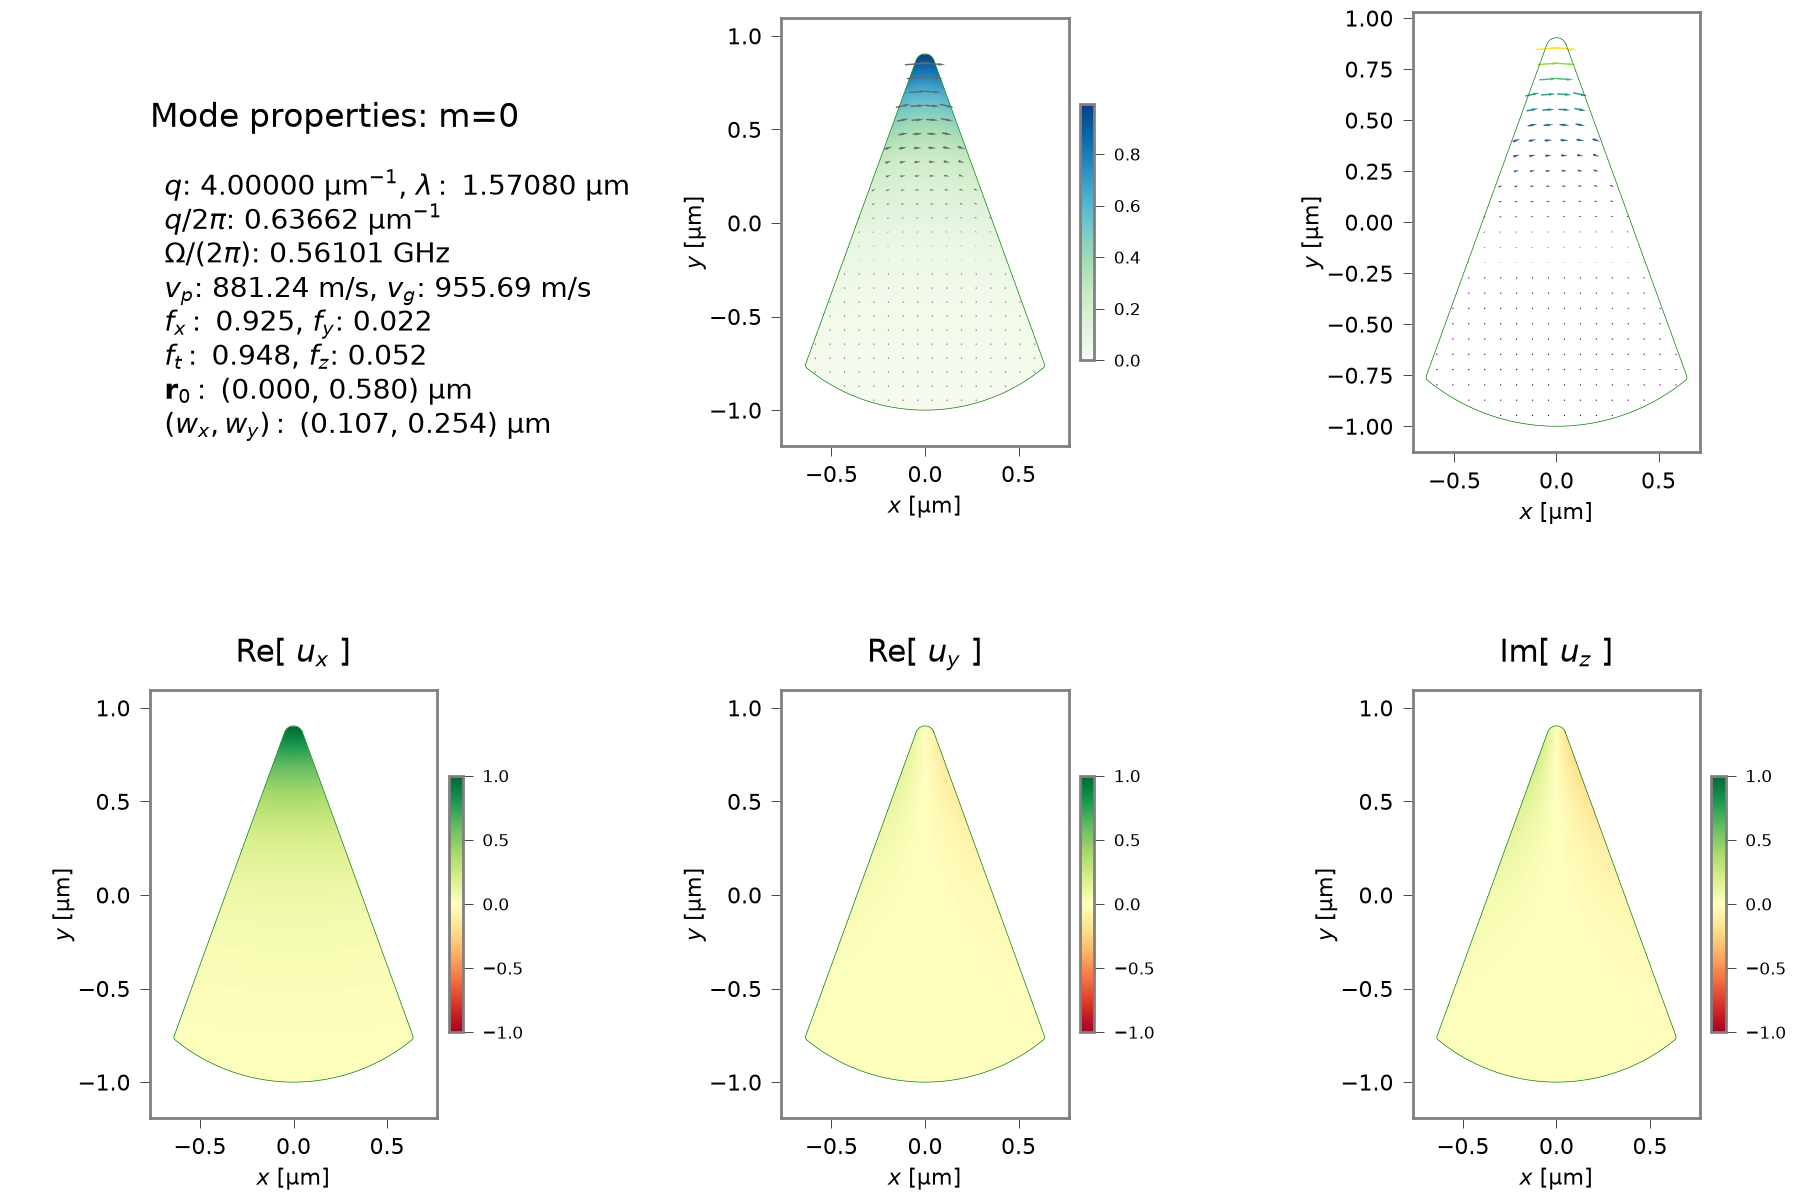

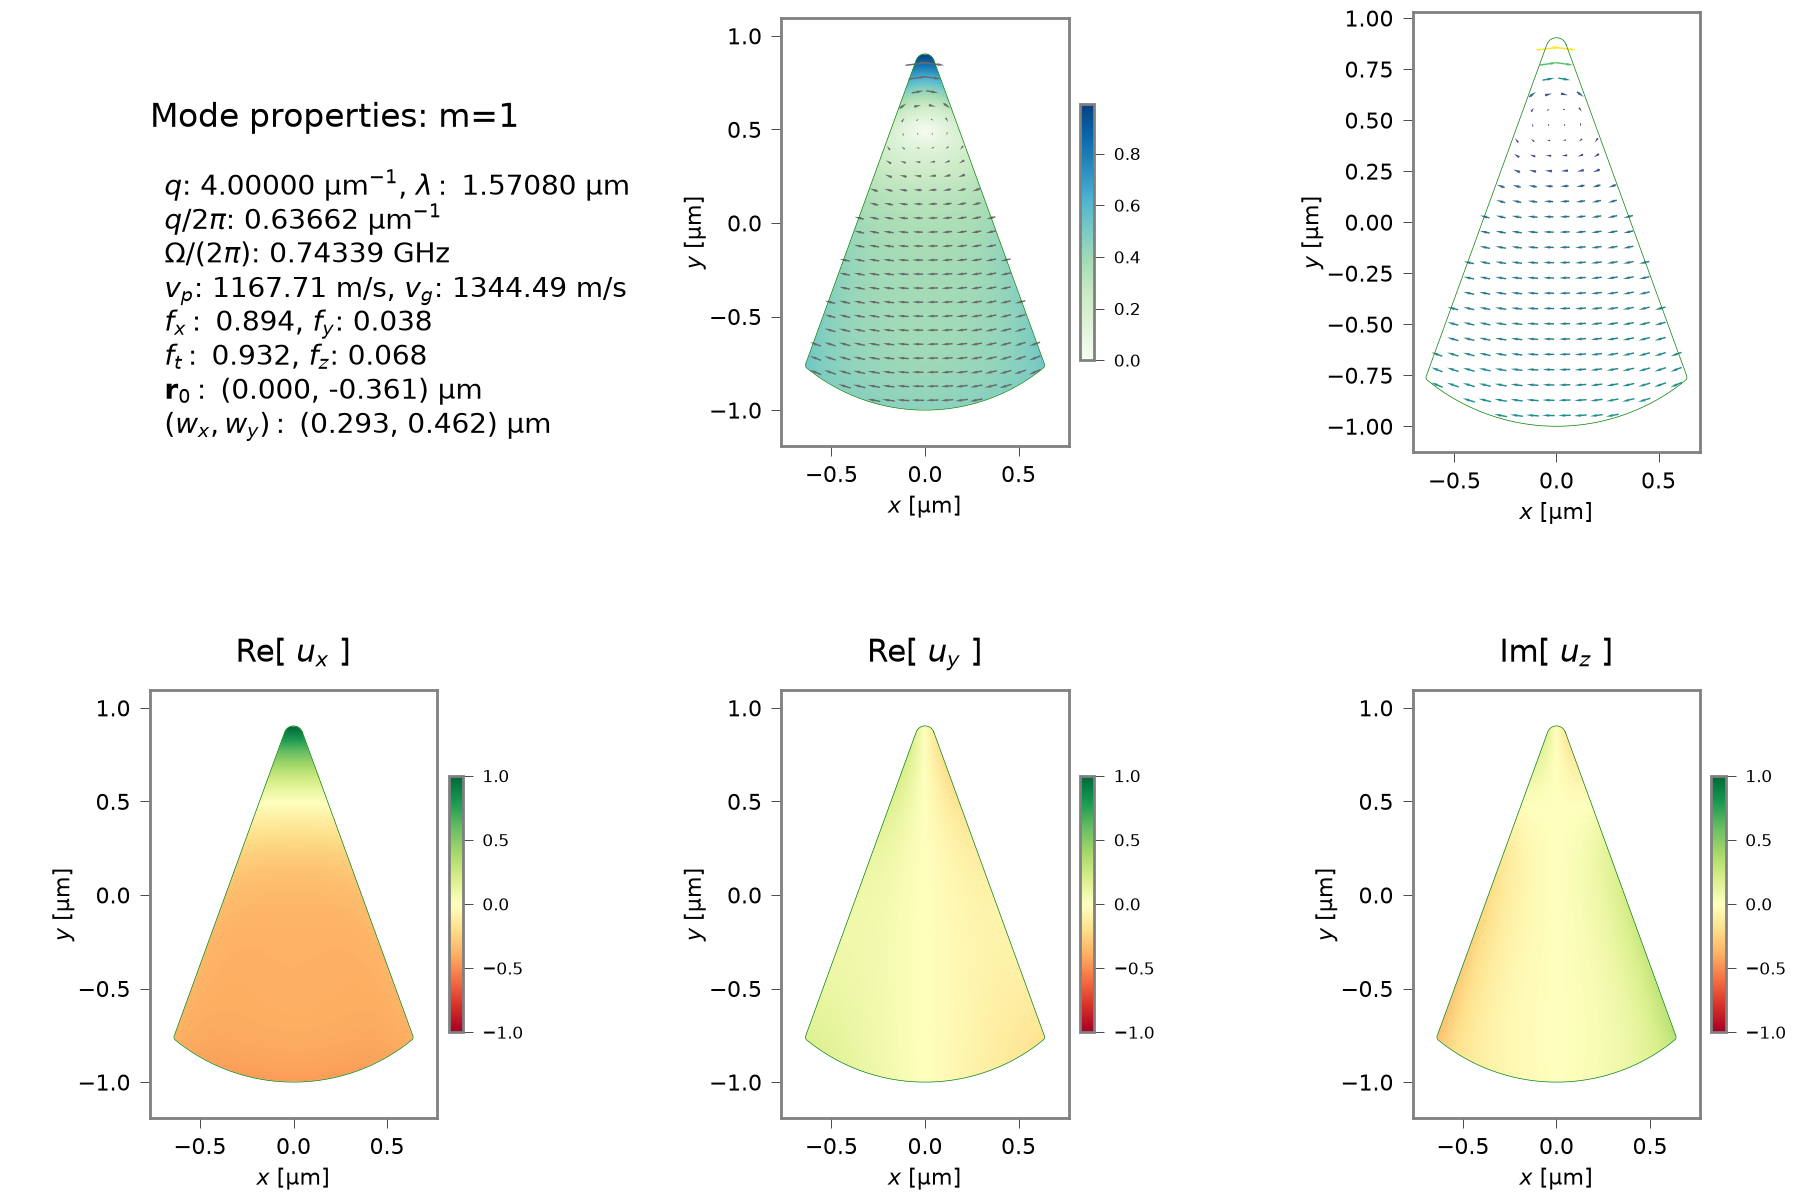

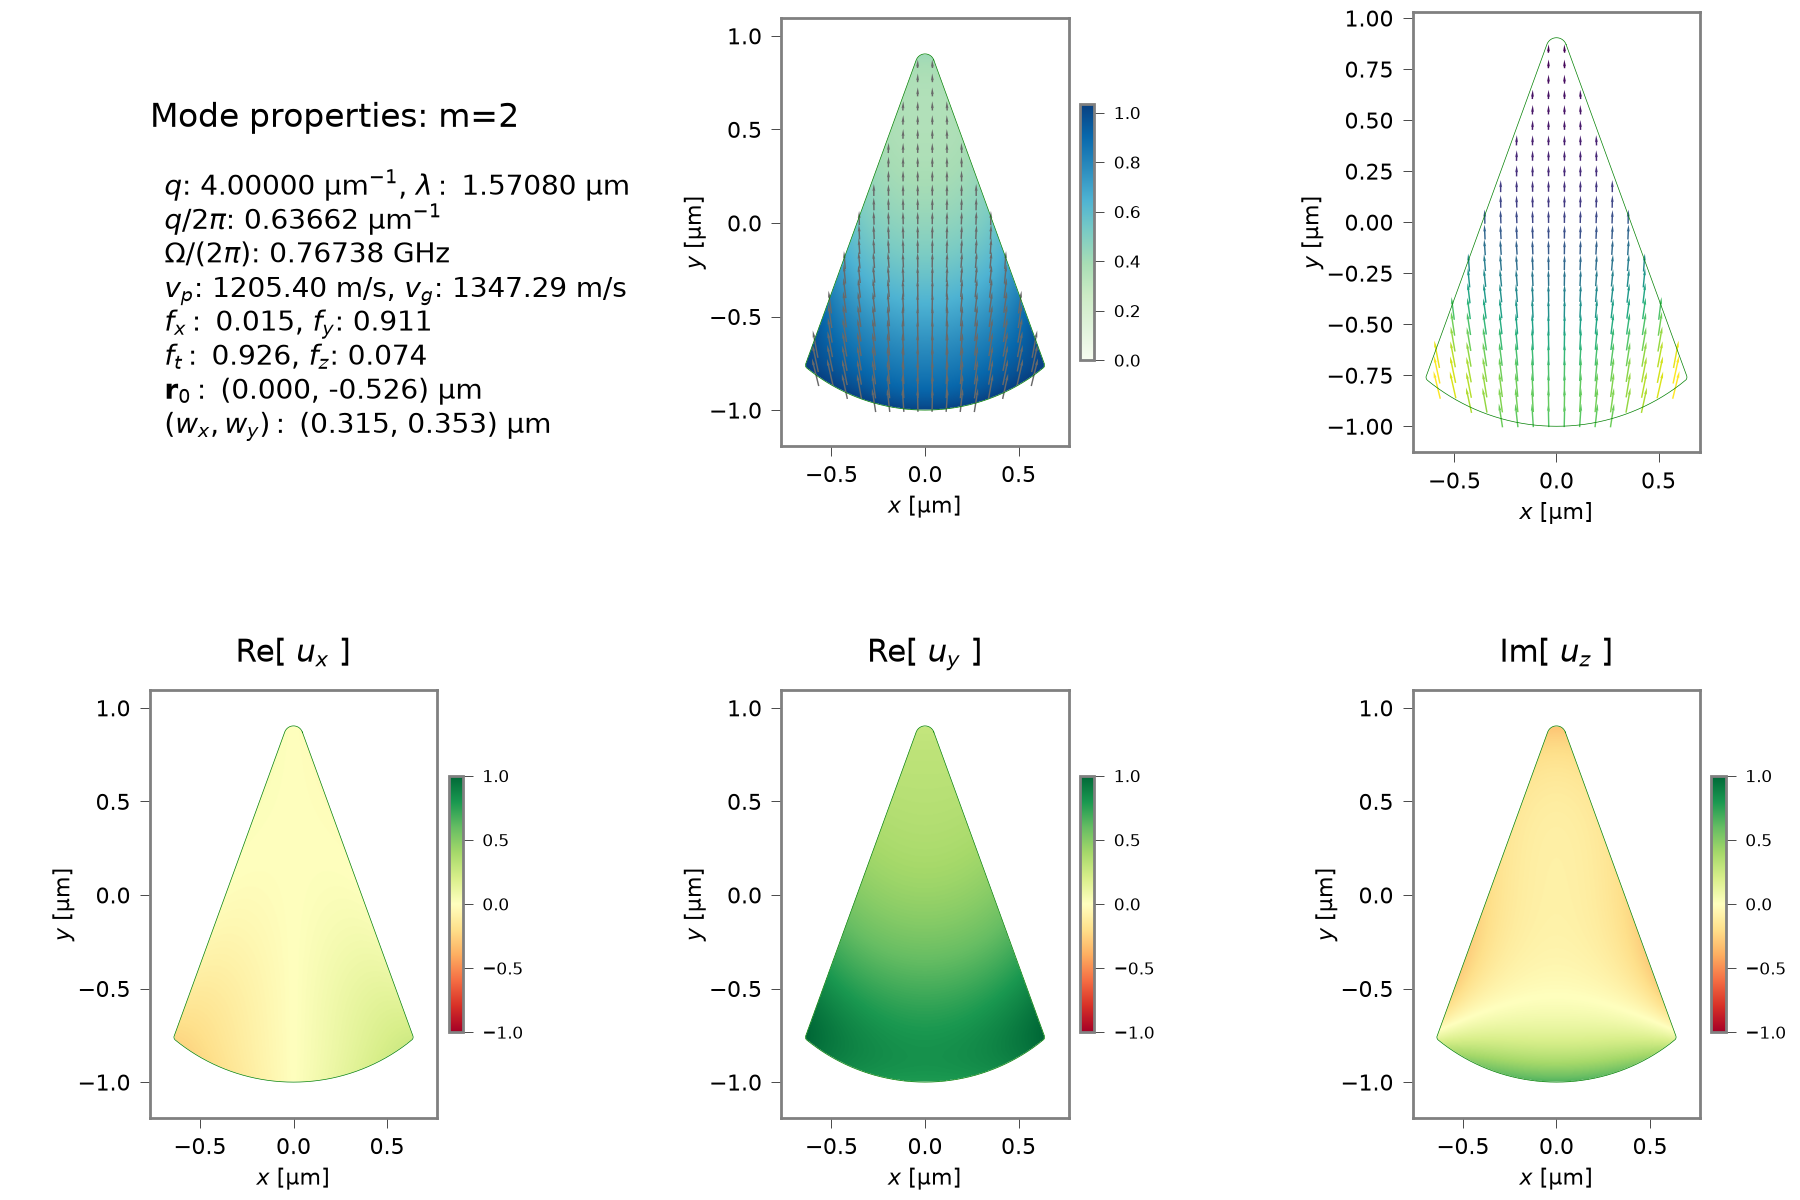

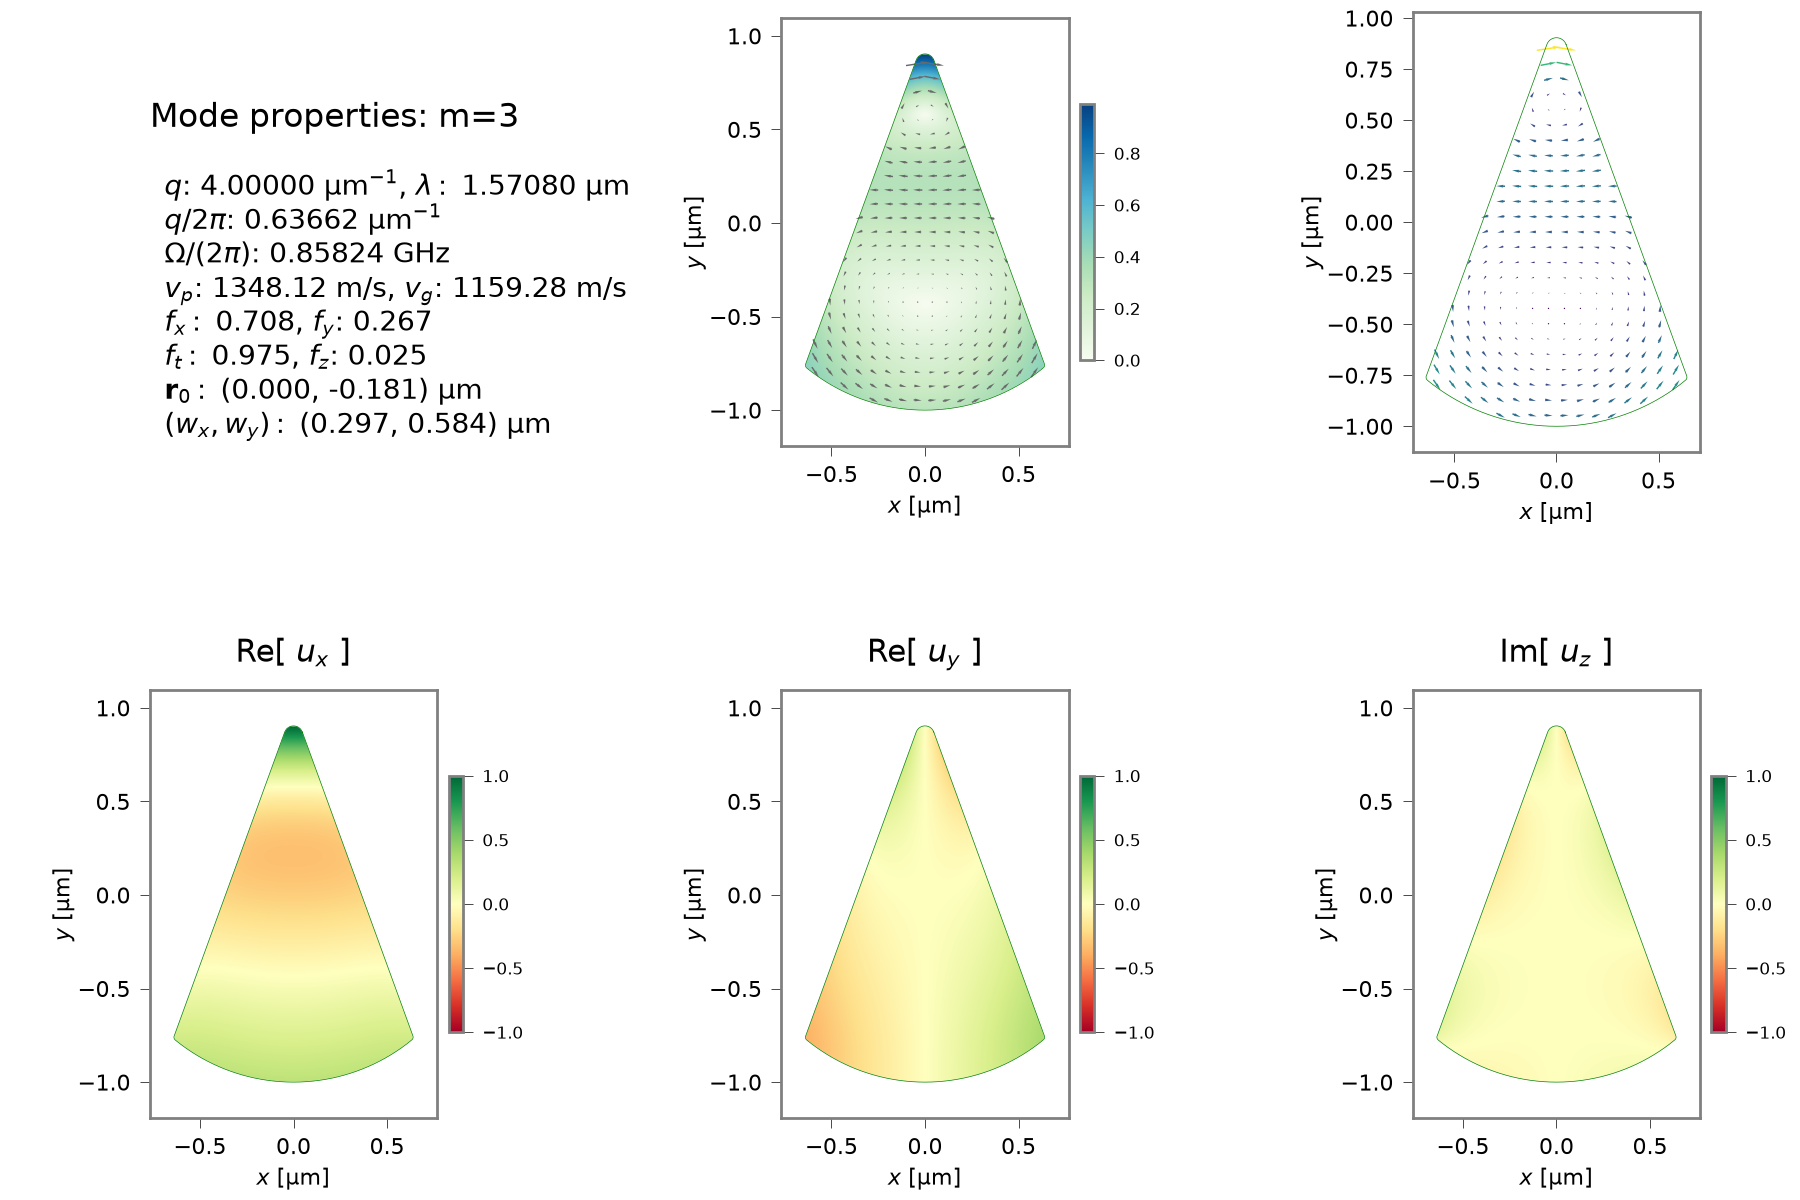

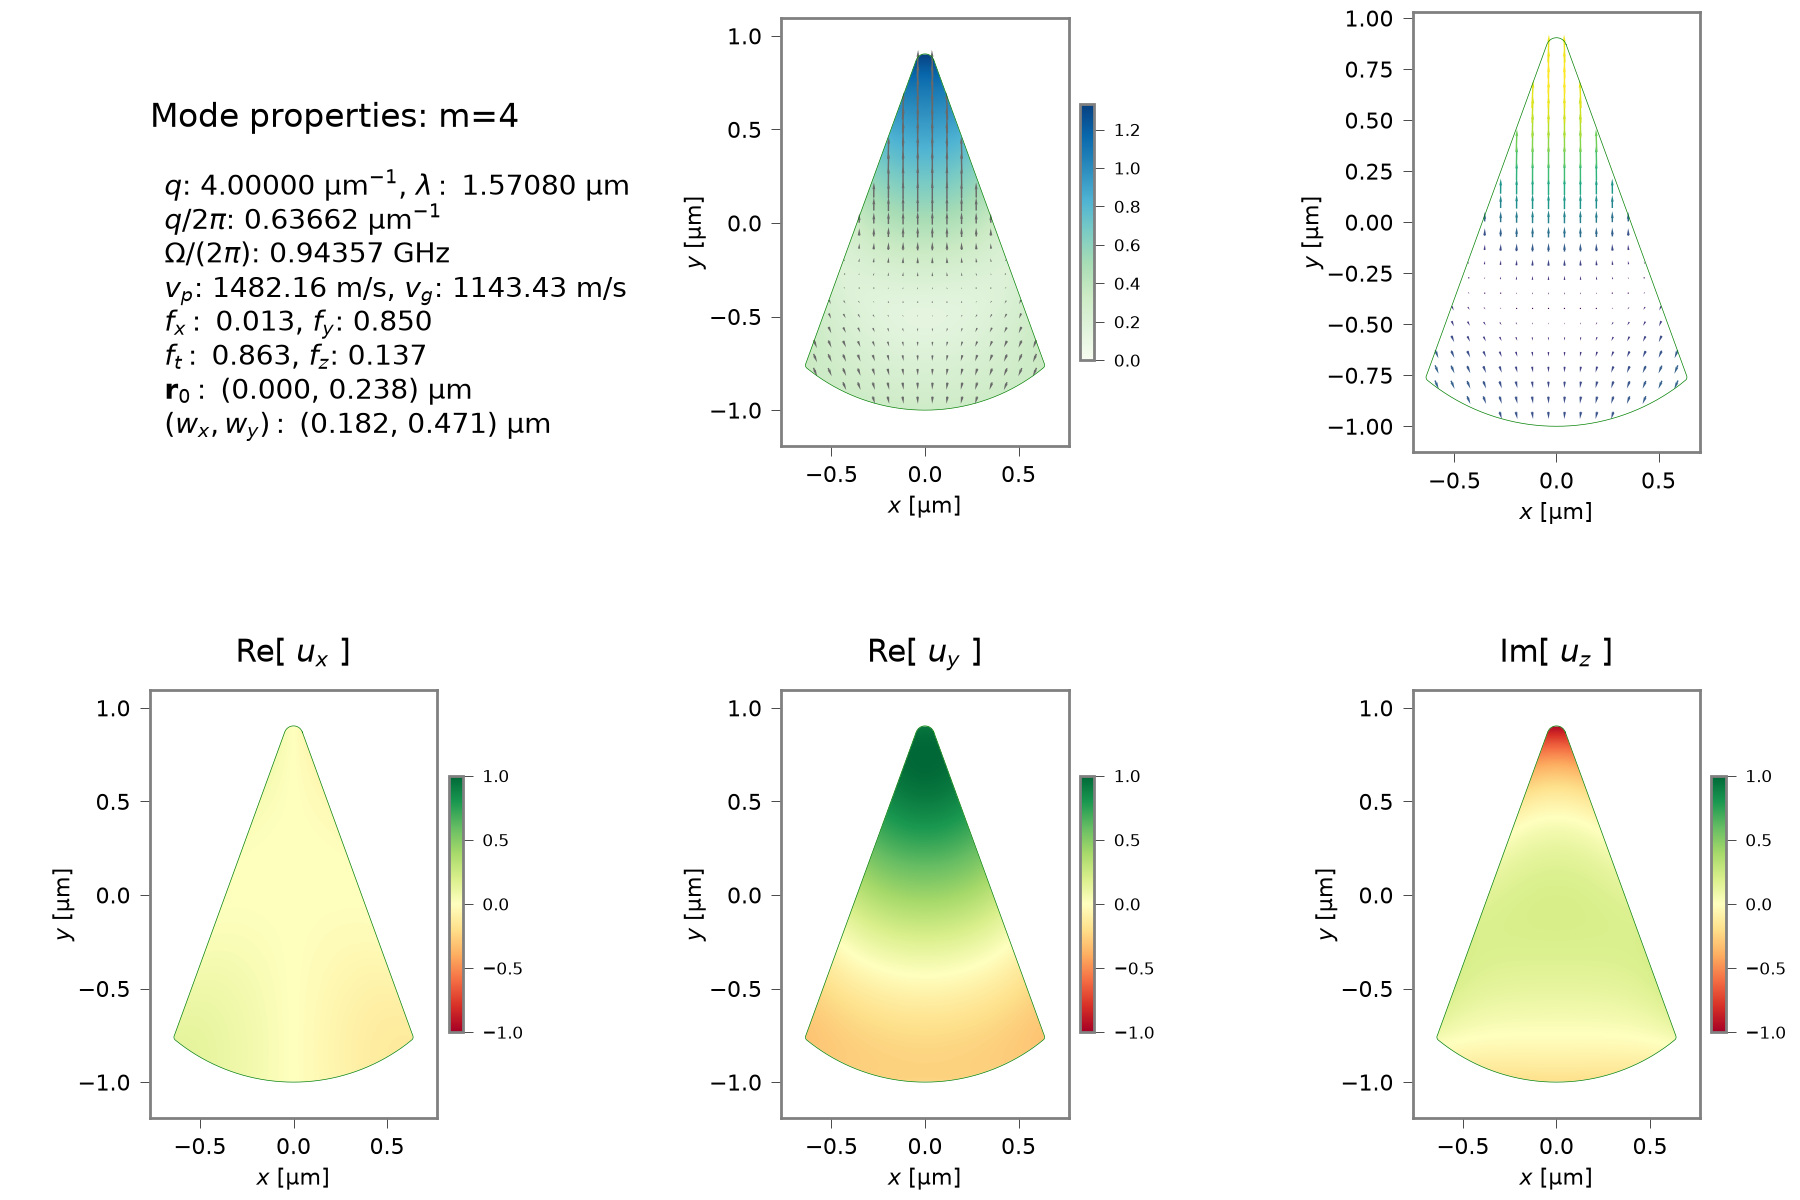

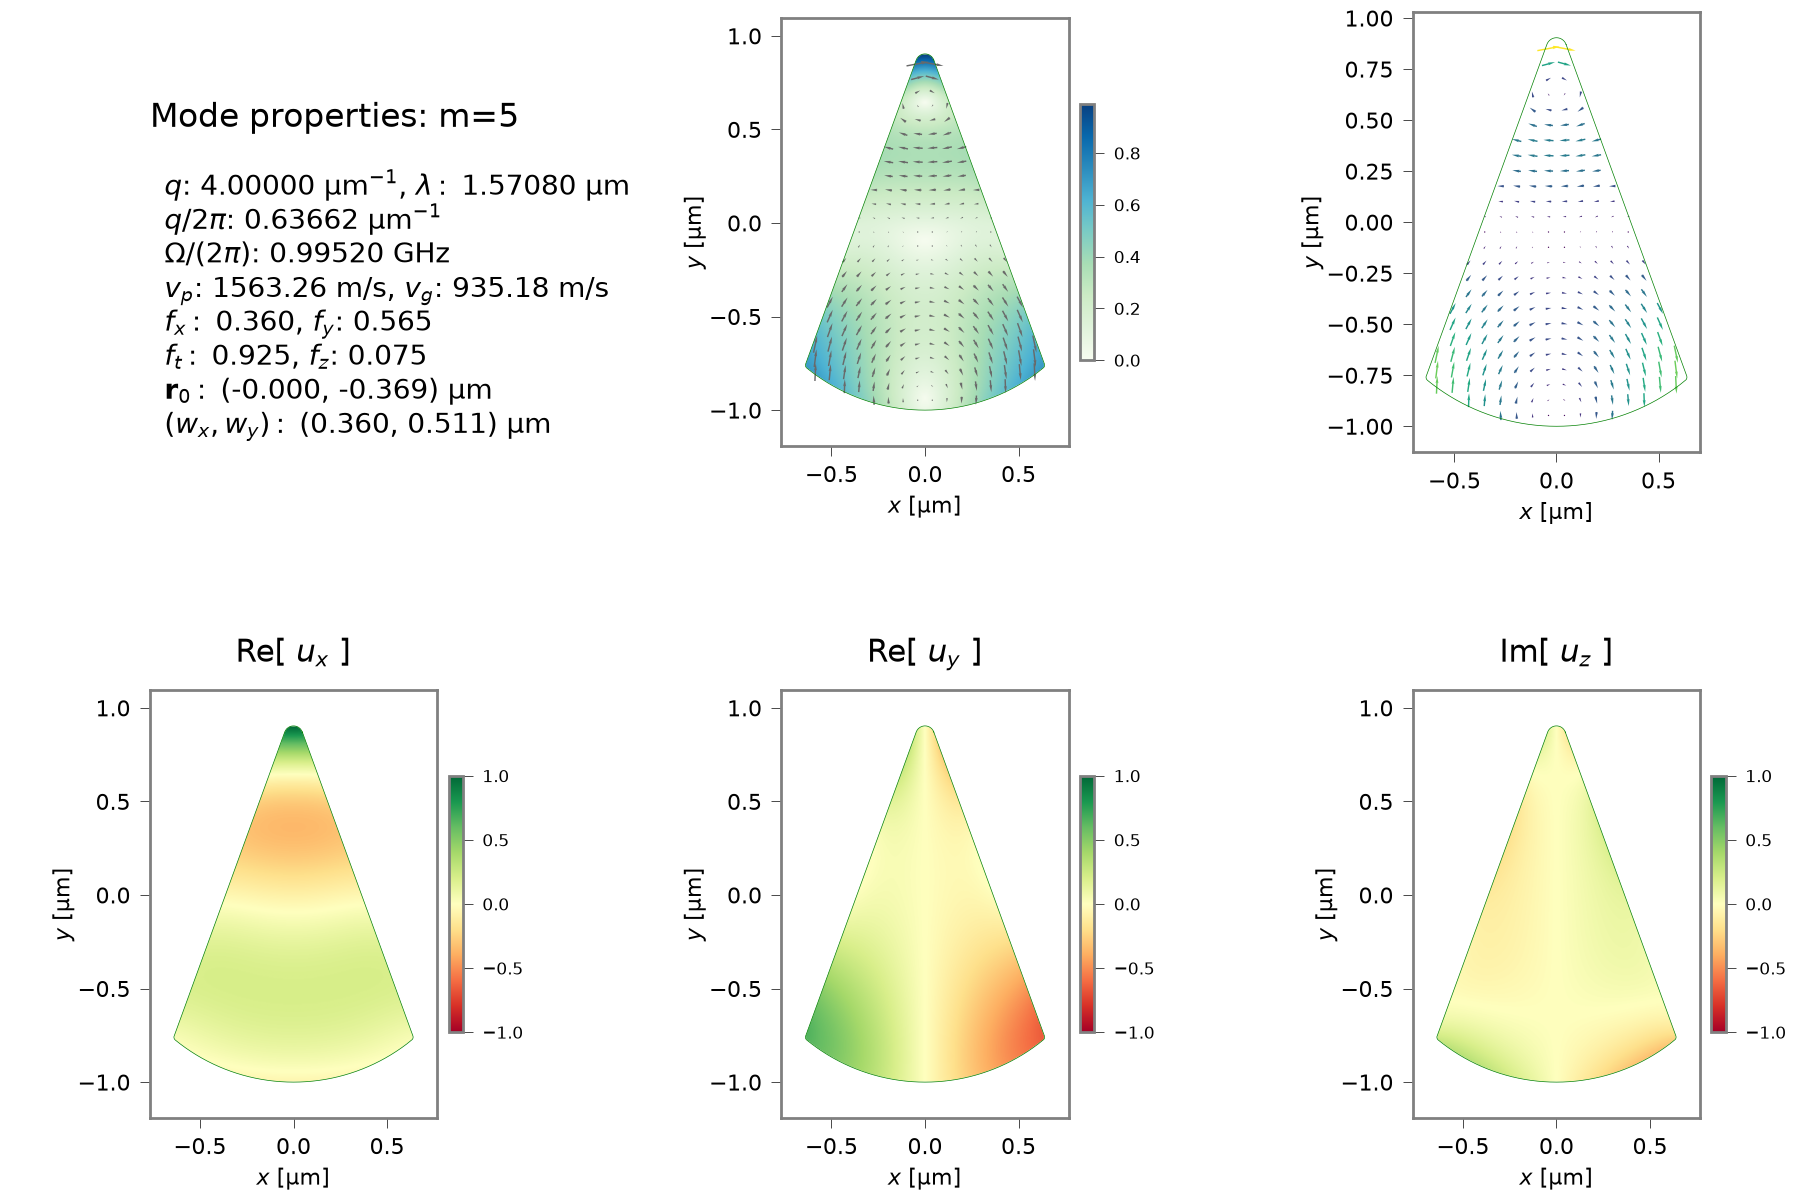

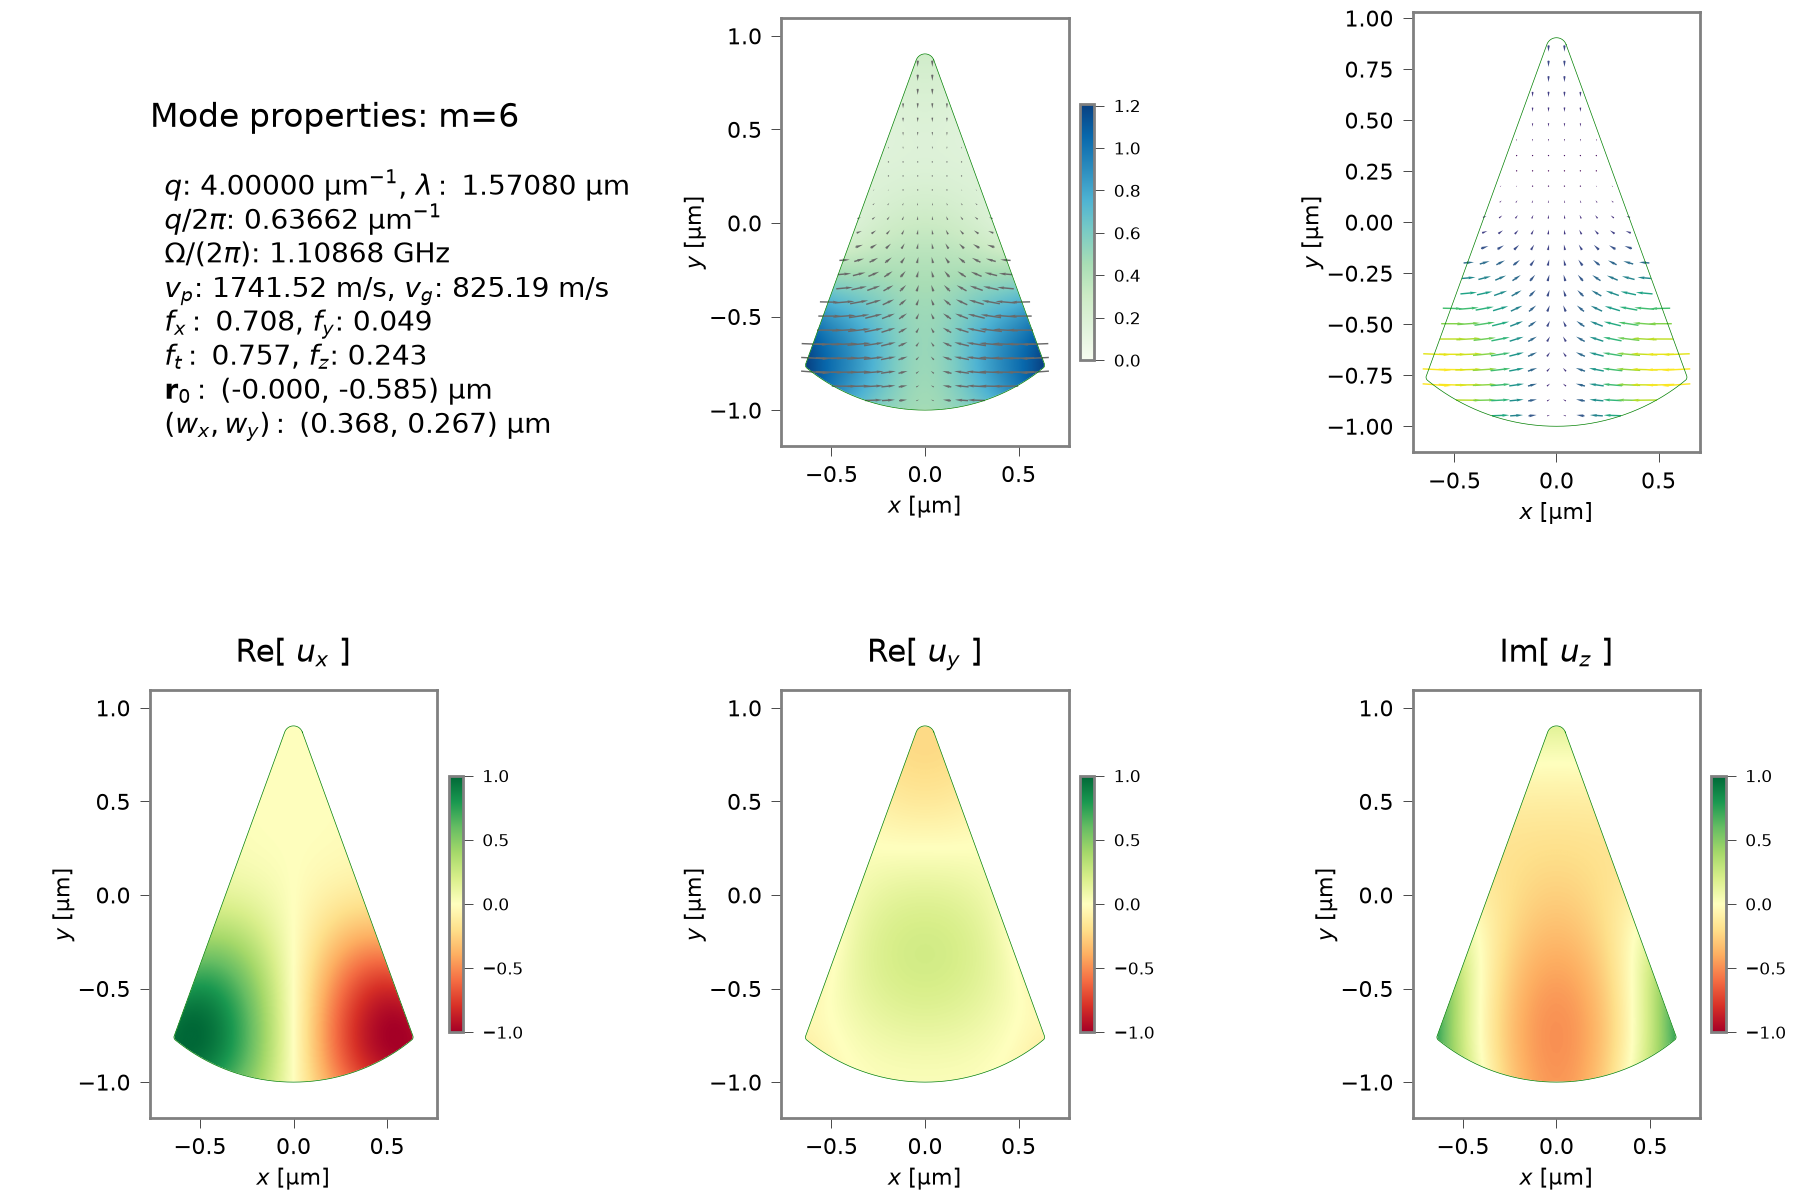

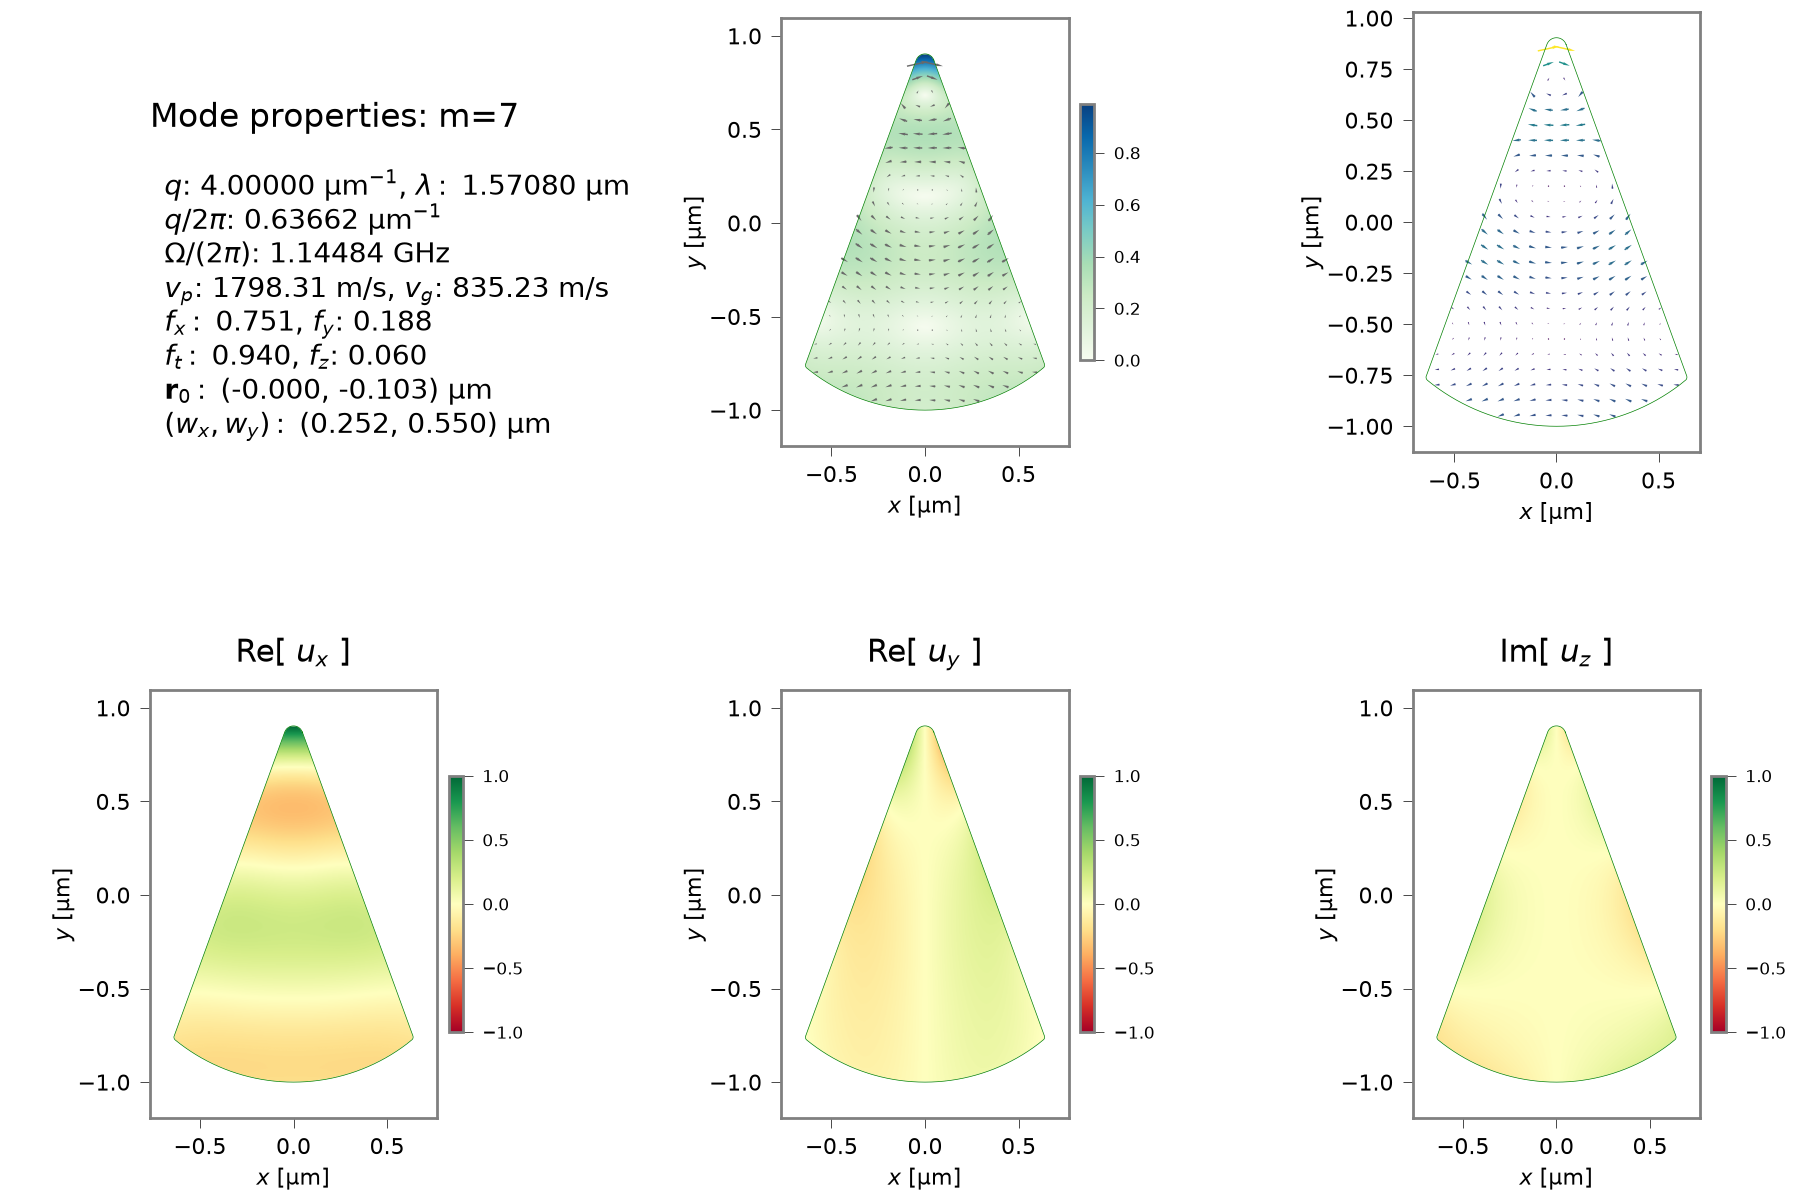

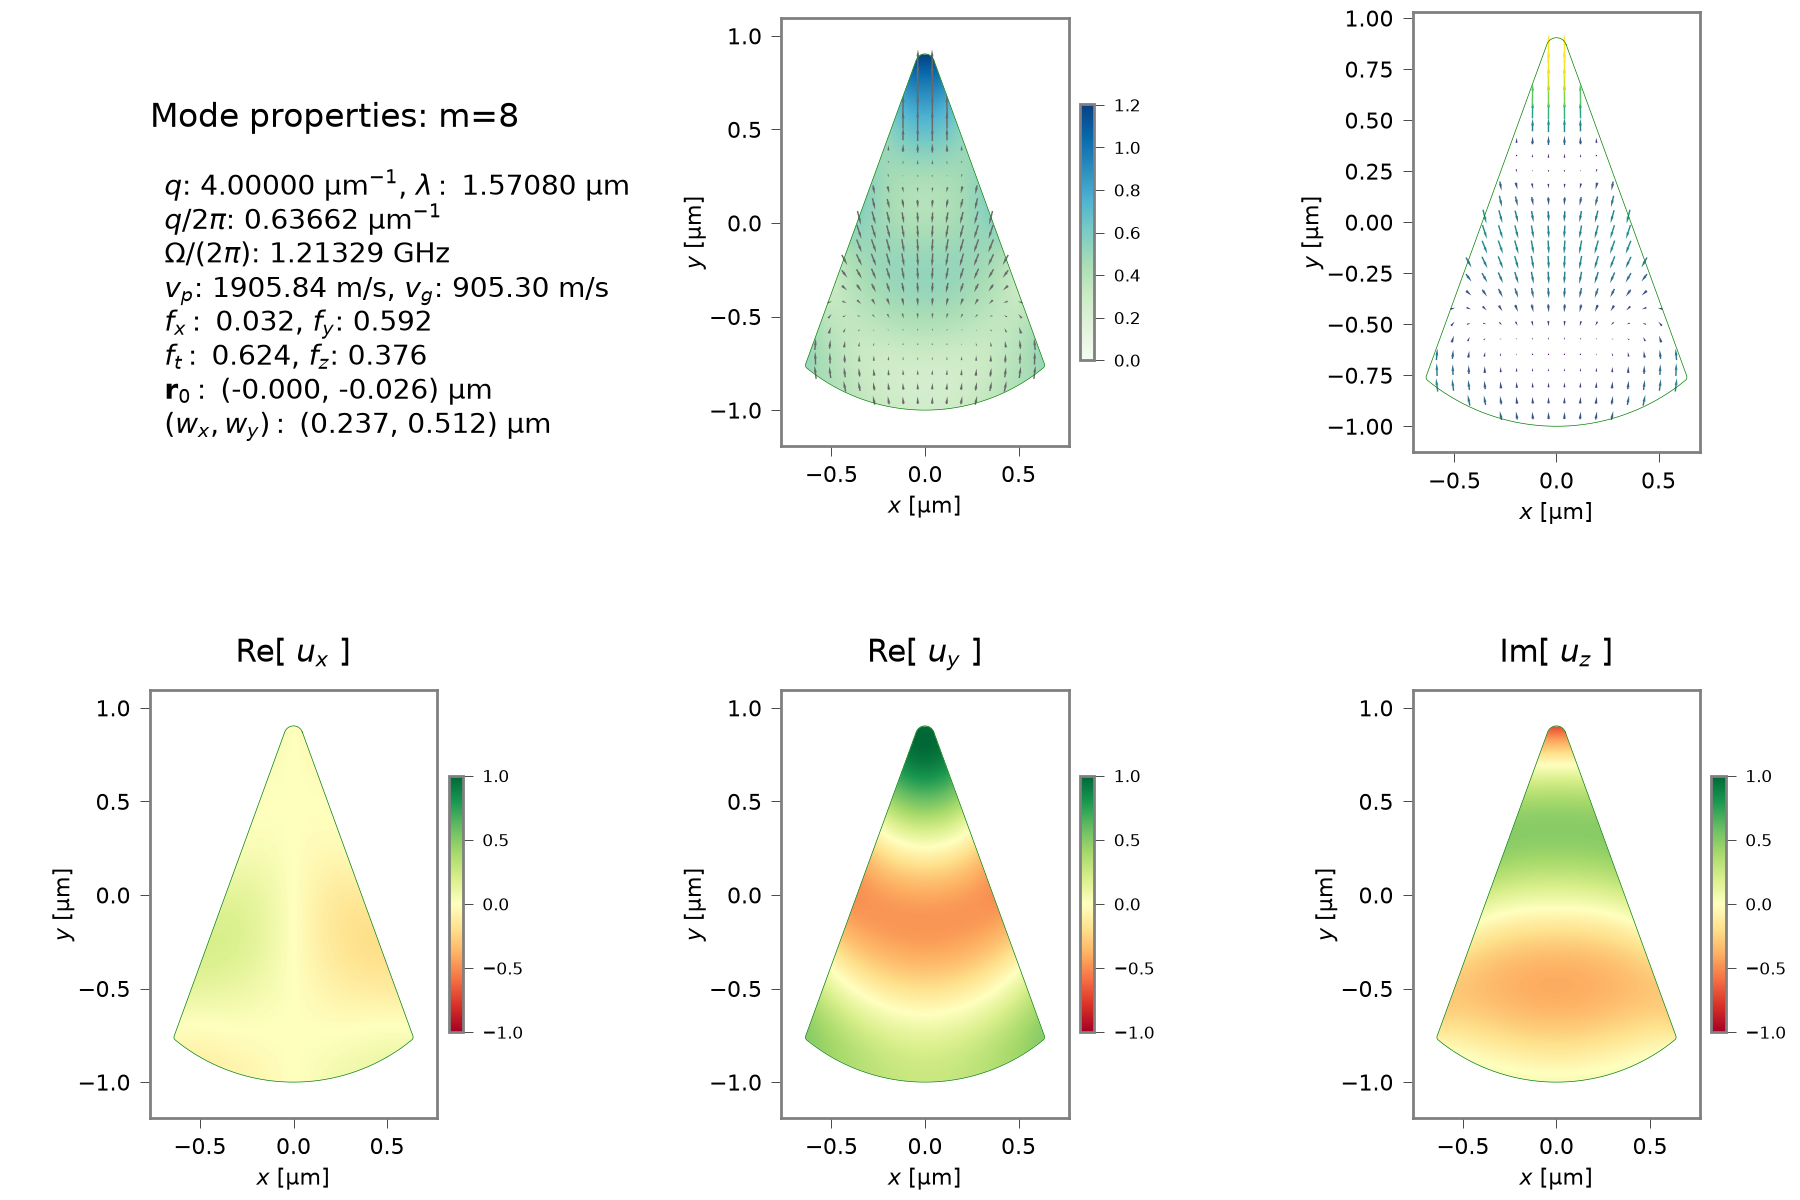

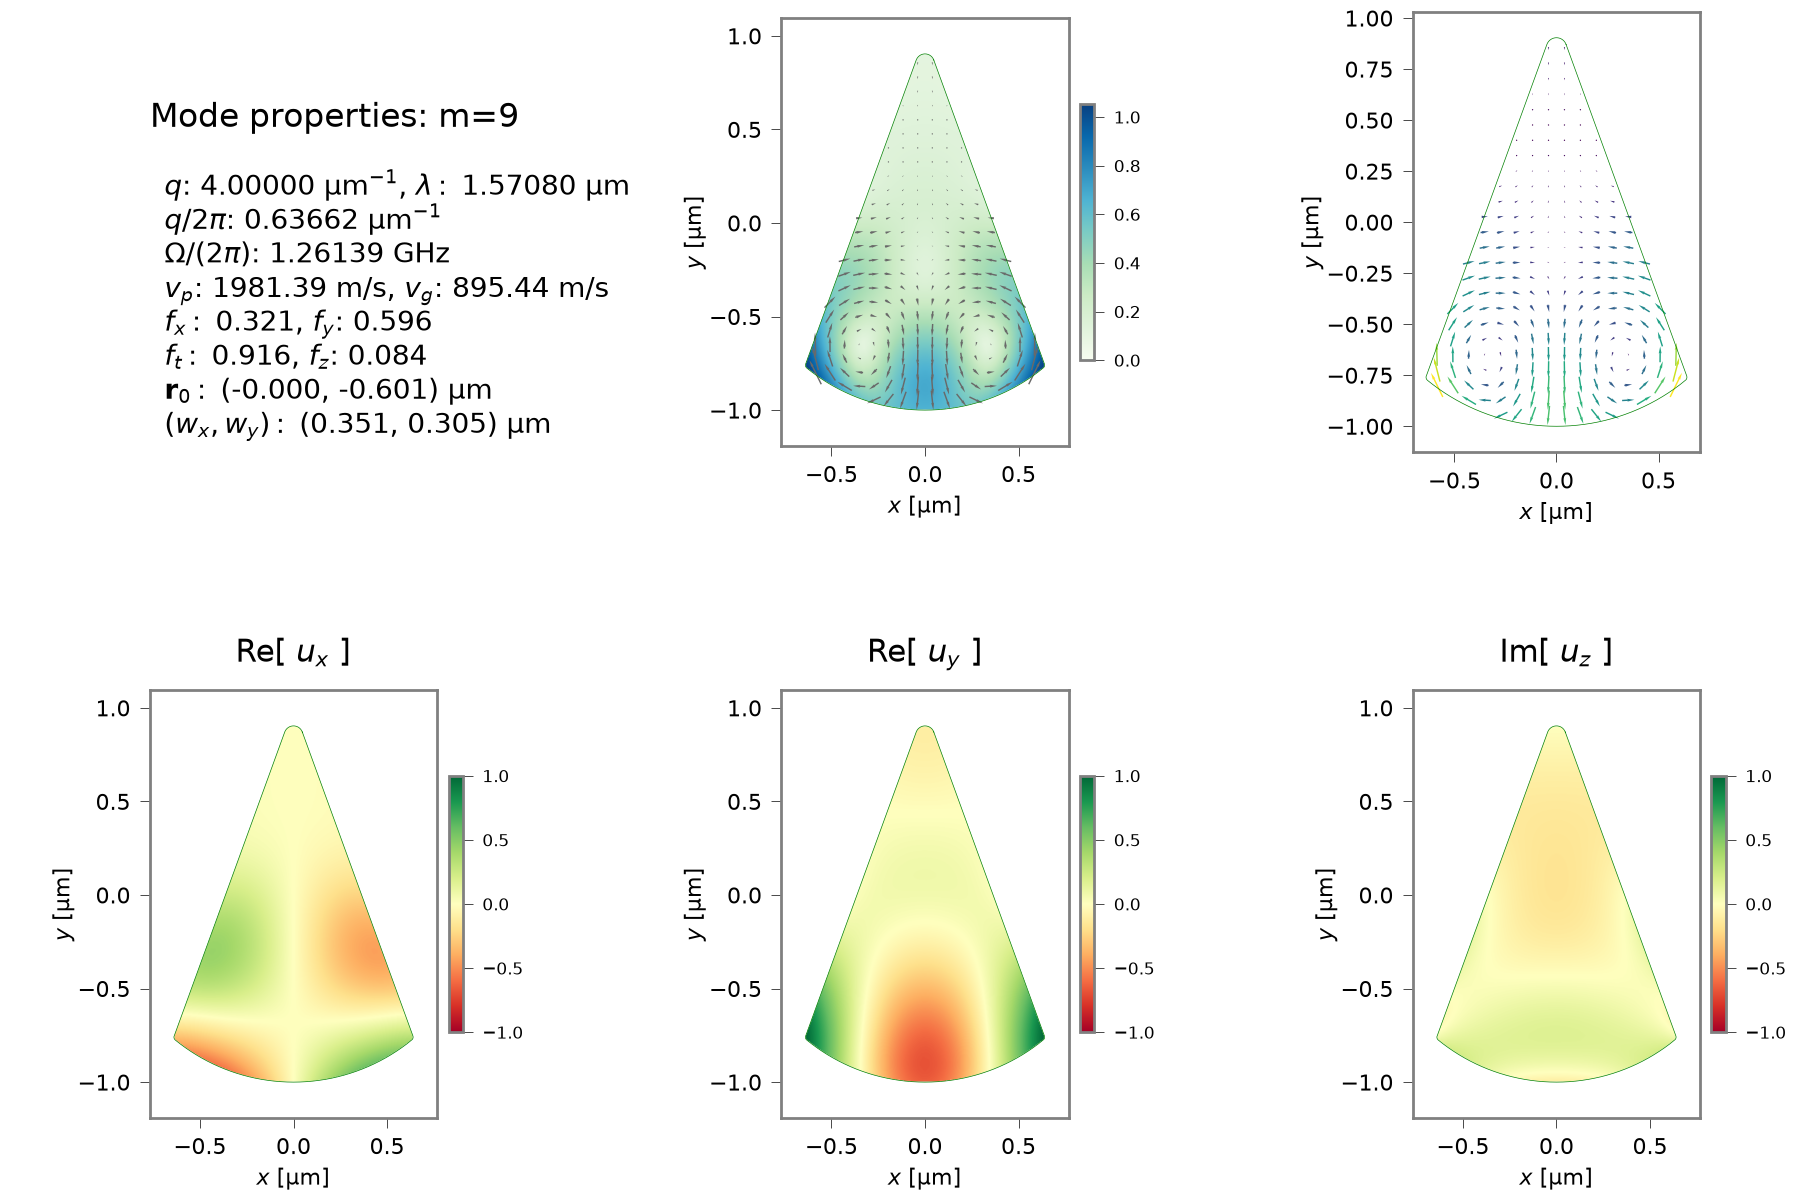

In [21]:
display_pngs(nbapp.outdir_fields_path(prefix), "AC*_mode_[0]?.png", imsize=(600,600), trim=(0.05, 0.1, 0.05, 0.15))